# ALS Forest Height vs BIOMASS L2A Forest Height — validation

Queries the ALS (Global Canopy Atlas) and BIOMASS L2A FH products from the ESA MAAP catalog and compares them on the
BIOMASS grid. Every figure, table and statistic is saved to `outputs/`:

| | |
|---|---|
| `outputs/report.txt` | all statistics and tables in one text file (ends with **KEY NUMBERS FOR THE SLIDES**) |
| `outputs/figures/*.png` | every figure, 200 dpi |
| `outputs/tables/*.csv` | every table |
| `outputs/maps/*.html` | interactive maps |
| `outputs/data/*.csv` | matched pixels |

In [1]:
import datetime as dt
import os
import pathlib
import sys
import traceback
from concurrent.futures import ThreadPoolExecutor, as_completed
from contextlib import contextmanager

import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib import colors as mcolors
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch
from matplotlib.ticker import FixedLocator, ScalarFormatter, NullFormatter

import folium
from folium import GeoJson
import geopandas as gpd
import numpy as np
import pandas as pd
import rasterio as rio
import rioxarray 
import xarray as xr
from IPython.display import display
from pyproj import Transformer
from pystac_client import Client
from rasterio.enums import Resampling
from shapely.geometry import shape
from shapely.validation import make_valid

### Define settings for the analysis

In [2]:
REF = "als_mean"               # ALS reference height: mean ALS height inside each BIOMASS pixel
N_TILES = None                 # None = all ALS tiles
N_WORKERS = 4                  # tiles downloaded in parallel
MAX_GAP_DAYS = 730             # max time between ALS flight and BIOMASS acquisition
MIN_COVER = 0.8                # min fraction of a BIOMASS pixel covered by ALS data
MIN_ALS_H = 1.0                # pixels with ALS mean height below this are dropped in the scatter
CANOPY_HT = 5.0                # m, threshold for canopy

ALS_ASSET = "enclosure_chm_lspikefree_tif"   # ALS canopy height model (spike free)
FH_ASSET = "enclosure_i_fh_tiff"             # BIOMASS FH
FHQ_ASSET = "enclosure_i_quality_tiff"       # BIOMASS FH quality
CATALOG_URL = "https://catalog.maap.eo.esa.int/catalogue/"

OUT = pathlib.Path("outputs")                
FIG_DIR, TAB_DIR, MAP_DIR, DATA_DIR = (OUT / d for d in ("figures", "tables", "maps", "data"))
CACHE_DIR = pathlib.Path("cache_tiles")       
for d in (FIG_DIR, TAB_DIR, MAP_DIR, DATA_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)
REPORT = OUT / "report.txt"

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)

TOKEN = os.environ.get("MAAP_CATALOGUE_ACCESS_TOKEN")
if not TOKEN:
    raise RuntimeError("Environment variable MAAP_CATALOGUE_ACCESS_TOKEN is not set. "
                       "Set it first:  export MAAP_CATALOGUE_ACCESS_TOKEN=...")

### Report functions

In [37]:
REPORT.write_text("")
FIGURES, FAILED_SECTIONS = [], []


def rep(*parts):
    text = " ".join(str(x) for x in parts)
    print(text, flush=True)
    with open(REPORT, "a", encoding="utf-8") as f:
        f.write(text + "\n")


def rep_table(title, df, csv_name=None, nd=2):
    rep(f"\n--- {title} ---")
    rep(df.round(nd).to_string() if hasattr(df, "round") else df)
    if csv_name:
        df.to_csv(TAB_DIR / f"{csv_name}.csv")


def save(fig, name):
    """Save a figure for the slides (PNG, 200 dpi) and free memory."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    FIGURES.append(path.name)
    rep(f"  [figure] {path}")


@contextmanager
def section(title, critical=False):
    """A report chapter. If it fails, the error is written to the report and the script
    continues with the next section (unless critical=True: then the script stops)."""
    rep("\n" + "=" * 90 + f"\n{title}\n" + "=" * 90)
    try:
        yield
    except Exception:
        rep(f"!! SECTION FAILED: {title}\n{traceback.format_exc()}")
        FAILED_SECTIONS.append(title)
        if critical:
            rep("Critical section failed -> stopping.")
            raise


def stats(y_ref, y_est):
    d = y_est - y_ref
    r = np.corrcoef(y_ref, y_est)[0, 1] if len(d) > 2 else np.nan
    return {"n": len(d), "bias": d.mean(), "RMSE": np.sqrt((d ** 2).mean()),
            "rel_RMSE_%": 100 * np.sqrt((d ** 2).mean()) / y_ref.mean(), "R2": r ** 2}


def vstats(y_ref, y_est):
    """Full set of validation metrics. y_ref = ALS, y_est = BIOMASS."""
    y_ref, y_est = np.asarray(y_ref, float), np.asarray(y_est, float)
    ok = np.isfinite(y_ref) & np.isfinite(y_est)
    y_ref, y_est = y_ref[ok], y_est[ok]
    n = len(y_ref)
    if n < 3:
        return {"n": n}
    d = y_est - y_ref
    rmse = np.sqrt(np.mean(d ** 2))
    r = np.corrcoef(y_ref, y_est)[0, 1]
    slope, intercept = np.polyfit(y_ref, y_est, 1)
    ccc = (2 * np.cov(y_ref, y_est, bias=True)[0, 1]
           / (y_ref.var() + y_est.var() + (y_ref.mean() - y_est.mean()) ** 2))
    return {
        "n": n, "ALS_mean": y_ref.mean(), "FH_mean": y_est.mean(),
        "bias": d.mean(), "median_resid": np.median(d),
        "MAE": np.abs(d).mean(), "RMSE": rmse,
        "ubRMSE": d.std(),                                       # RMSE after removing bias
        "NMAD": 1.4826 * np.median(np.abs(d - np.median(d))),   # robust spread
        "rel_RMSE_%": 100 * rmse / y_ref.mean(),
        "R2": r ** 2, "CCC": ccc, "slope": slope, "intercept": intercept,
        "within_5m_%": 100 * np.mean(np.abs(d) <= 5),
        "within_10m_%": 100 * np.mean(np.abs(d) <= 10),
    }


def log_ticks(a, lo, hi, x=True, y=True):
    """Readable tick labels (1, 2, 5, 10, 20 ...) on log axes."""
    ticks = [t for t in [1, 2, 5, 10, 20, 30, 50, 70, 100] if lo <= t <= hi]
    for axis, on in ((a.xaxis, x), (a.yaxis, y)):
        if on:
            axis.set_major_locator(FixedLocator(ticks)); axis.set_major_formatter(ScalarFormatter())
            axis.set_minor_formatter(NullFormatter())


def gdal_env():
    return rio.Env(GDAL_HTTP_HEADERS=f"Authorization: Bearer {TOKEN}",
                   GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
                   GDAL_HTTP_MULTIRANGE="YES", GDAL_HTTP_MERGE_CONSECUTIVE_RANGES="YES")

In [38]:
t_start = dt.datetime.now()
rep(f"ALS vs BIOMASS L2A forest height validation — started {t_start:%Y-%m-%d %H:%M}")
rep(f"Settings: REF={REF}  N_TILES={N_TILES}  MAX_GAP_DAYS={MAX_GAP_DAYS}  MIN_COVER={MIN_COVER}  "
    f"MIN_ALS_H={MIN_ALS_H}  CANOPY_HT={CANOPY_HT}  workers={N_WORKERS}")
rep(f"Outputs in: {OUT.resolve()}")

ALS vs BIOMASS L2A forest height validation — started 2026-10-16 09:27
Settings: REF=als_mean  N_TILES=None  MAX_GAP_DAYS=730  MIN_COVER=0.8  MIN_ALS_H=1.0  CANOPY_HT=5.0  workers=4
Outputs in: /home/jovyan/biomass-hackathon-2026/topics/06-biomass-validation/outputs


In [40]:
### Query the catalog: ALS collections + overlapping BIOMASS FH L2A products

In [36]:
with section("2-3. ESA MAAP catalog: ALS collections and BIOMASS FH L2A products", critical=True):
    catalog = Client.open(CATALOG_URL)
    results = catalog.collection_search(filter="platform='Air-based Platform'",
                                        datetime="2025-06-01T00:00:00.000Z/..")
    rep(f"{results.matched()} ALS collections found.")
    als_df = pd.json_normalize(results.collection_list_as_dict(), record_path=["collections"])
    ALS_COLLECTIONS = als_df["id"].tolist()
    rep_table("ALS collections", als_df[[c for c in ["id", "title", "extent.temporal.interval",
                                                      "extent.spatial.bbox"] if c in als_df]].set_index("id"),
              "03_als_collections")

    def items_to_gdf(items, source):
        rows = [{"id": it.id, "datetime": pd.Timestamp(it.datetime), "source": source,
                 "geometry": shape(it.geometry), "item": it} for it in items]
        return gpd.GeoDataFrame(rows, geometry="geometry", crs="EPSG:4326")

    als_search = catalog.search(collections=ALS_COLLECTIONS, limit=100, max_items=500)
    rep("ALS items matched:", als_search.matched())
    gdf_als = items_to_gdf(list(als_search.items()), "ALS")
    rep("ALS bbox:", gdf_als.total_bounds.round(2))

    bbox = list(gdf_als.total_bounds)
    fh_search = catalog.search(collections=["BiomassLevel2a"], filter="productType='FP_FH__L2A'",
                               filter_lang="cql2-text", bbox=bbox, limit=100, max_items=500)
    rep("FH L2A items matched:", fh_search.matched())
    gdf_fh = items_to_gdf(list(fh_search.items()), "BIOMASS FH L2A")
    rep(f"ALS items: {len(gdf_als)}   |   FH L2A items: {len(gdf_fh)}")


2-3. ESA MAAP catalog: ALS collections and BIOMASS FH L2A products
1 ALS collections found.

--- ALS collections ---
                                   title                                extent.temporal.interval            extent.spatial.bbox
id                                                                                                                             
ALS_CHM_Amazon_SFB  ALS CHM Amazon - SFB  [[2011-01-01T00:00:00.000Z, 2025-12-31T23:59:59.000Z]]  [[-64.32, -10, -51.37, 1.86]]
ALS items matched: 479
ALS bbox: [-64.13  -9.59 -51.39   1.85]
FH L2A items matched: 304
!! SECTION FAILED: 2-3. ESA MAAP catalog: ALS collections and BIOMASS FH L2A products
Traceback (most recent call last):
  File "/tmp/ipykernel_611/3288116150.py", line 35, in section
    yield
  File "/tmp/ipykernel_611/2364236682.py", line 26, in <module>
    gdf_fh = items_to_gdf(list(fh_search.items()), "BIOMASS FH L2A")
                          ^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/conda/lib/python3.1

APIError: {"error": {
  "code": 400,
  "message": "Invalid token: 47121ddd-d4de-5a26-8e99-5ea358a8ff52",
  "errors": [{"location": "token"}]
}}

### 4. spatial and temporal overlap

In [6]:
with section("4. Spatial and temporal overlap", critical=True):
    for name, g in (("ALS", gdf_als), ("FH", gdf_fh)):
        rep(f"invalid geometries {name}: {(~g.is_valid).sum()} / {len(g)}")
        g["geometry"] = g.geometry.apply(make_valid)

    pairs = gpd.sjoin(gdf_als, gdf_fh, how="inner", predicate="intersects", lsuffix="als", rsuffix="fh")
    ea = "EPSG:6933"
    als_geom = gdf_als.drop_duplicates("id").set_index("id").to_crs(ea).geometry
    fh_geom = gdf_fh.drop_duplicates("id").set_index("id").to_crs(ea).geometry

    def overlap_km2(a, f):
        try:
            return als_geom[a].intersection(fh_geom[f]).area / 1e6
        except Exception:
            return als_geom[a].buffer(0).intersection(fh_geom[f].buffer(0)).area / 1e6

    pairs["overlap_km2"] = [overlap_km2(a, f) for a, f in zip(pairs["id_als"], pairs["id_fh"])]
    pairs = pairs[pairs["overlap_km2"] > 0]
    pairs["dt_days"] = (pairs["datetime_fh"] - pairs["datetime_als"]).dt.days

    rep(f"Overlapping ALS/FH pairs: {len(pairs)}")
    rep(f"ALS tiles with >=1 BIOMASS overlap: {pairs['id_als'].nunique()} / {len(gdf_als)}")
    rep(f"Total overlap area: {pairs['overlap_km2'].sum():.1f} km²")
    rep_table("Top 10 pairs by overlap", pairs[["id_als", "id_fh", "overlap_km2", "dt_days"]]
              .sort_values("overlap_km2", ascending=False).head(10))
    rep_table("Time gap BIOMASS − ALS [days]", pairs["dt_days"].describe().round(0).to_frame())
    rep_table("ALS acquisition years", gdf_als["datetime"].dt.year.value_counts().sort_index().to_frame())
    covered = gdf_als[gdf_als["id"].isin(pairs["id_als"])]
    rep(f"ALS area with BIOMASS coverage: {covered.to_crs(ea).area.sum() / 1e6:.0f} km²")
    rep_table("Number of BIOMASS products overlapping each ALS tile",
              pairs.groupby("id_als").size().value_counts().sort_index().to_frame("n_als_tiles"))


4. Spatial and temporal overlap
invalid geometries ALS: 5 / 479
invalid geometries FH: 0 / 304
Overlapping ALS/FH pairs: 902
ALS tiles with >=1 BIOMASS overlap: 399 / 479
Total overlap area: 4627.9 km²

--- Top 10 pairs by overlap ---
                                                        id_als                                                                             id_fh  overlap_km2  dt_days
3    ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_BOM-FUTURO_2025_BFT01  BIO_FP_FH__L2A_20260517T222248_20260529T222315_T_G01_M03_C___T014_F163_02_DTEOUD        42.28      332
3    ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_BOM-FUTURO_2025_BFT01  BIO_FP_FH__L2A_20260917T101051_20260929T101120_T_G01_M05_C___T006_F303_02_DZ4XT8        42.28      455
4    ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_BOM-FUTURO_2025_BFT04  BIO_FP_FH__L2A_20260818T100637_20260830T100705_T_G01_M04_C___T006_F303_02_DXKOXF        28.65      425
4    ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_BOM-FUTURO_2025_BFT04  BIO_FP_FH__L2A_20260607T222300_2


4b. Footprint figure and interactive map


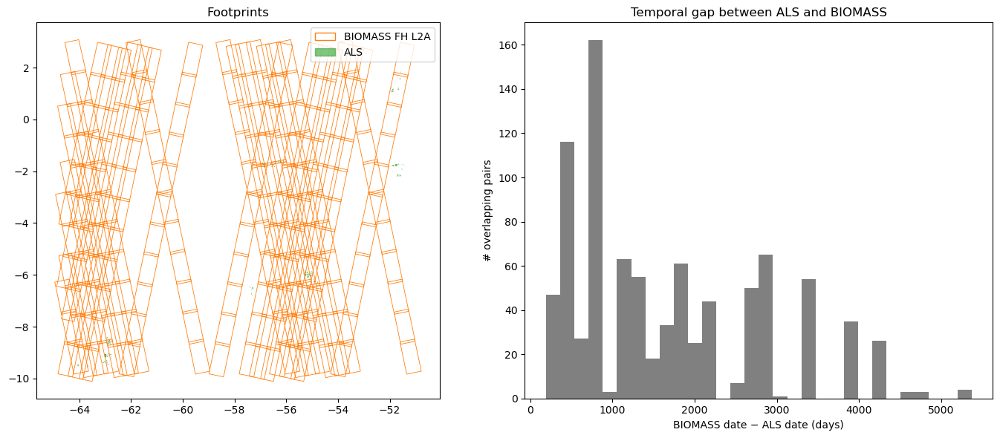

  [figure] outputs/figures/04_footprints_time_gap.png
  [map] outputs/maps/04_footprints.html


In [7]:
with section("4b. Footprint figure and interactive map"):
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    gdf_fh.boundary.plot(ax=ax[0], color="tab:orange", lw=0.6)
    gdf_als.plot(ax=ax[0], color="tab:green", alpha=0.6)
    ax[0].set_title("Footprints")
    ax[0].legend(handles=[Patch(edgecolor="tab:orange", facecolor="none", label="BIOMASS FH L2A"),
                          Patch(color="tab:green", alpha=0.6, label="ALS")])
    ax[1].hist(pairs["dt_days"], bins=30, color="grey")
    ax[1].set_xlabel("BIOMASS date − ALS date (days)"); ax[1].set_ylabel("# overlapping pairs")
    ax[1].set_title("Temporal gap between ALS and BIOMASS")
    plt.tight_layout(); save(fig, "04_footprints_time_gap")

    m = folium.Map(location=[np.mean(bbox[1::2]), np.mean(bbox[0::2])], zoom_start=8)
    GeoJson(gdf_fh[["id", "geometry"]], name="BIOMASS FH L2A",
            style_function=lambda f: {"color": "orange", "weight": 1, "fillOpacity": 0}).add_to(m)
    GeoJson(gdf_als[["id", "geometry"]], name="ALS",
            style_function=lambda f: {"color": "green", "weight": 1, "fillOpacity": 0.4}).add_to(m)
    folium.LayerControl().add_to(m)
    m.save(MAP_DIR / "04_footprints.html"); rep(f"  [map] {MAP_DIR / '04_footprints.html'}")
    display(m)

### 5. ONE biomass product per tile

In [8]:
with section("5. Pair selection", critical=True):
    recent = pairs[pairs["dt_days"].abs() <= MAX_GAP_DAYS]
    best_pairs = (recent.sort_values("dt_days", key=abs).drop_duplicates("id_als")
                  .sort_values("overlap_km2", ascending=False))
    rep(f"Pairs within {MAX_GAP_DAYS} days: {len(recent)} | ALS tiles kept: {len(best_pairs)}")
    als_by_id = gdf_als.drop_duplicates("id").set_index("id")["item"]
    fh_by_id = gdf_fh.drop_duplicates("id").set_index("id")["item"]
    todo = best_pairs if N_TILES is None else best_pairs.head(N_TILES)
    rep(f"Tiles to process: {len(todo)}")


5. Pair selection
Pairs within 730 days: 216 | ALS tiles kept: 105
Tiles to process: 105


### Functions for data extraction

In [9]:
def open_pair(als_item, fh_item):
    with gdal_env():
        als = rioxarray.open_rasterio(als_item.assets[ALS_ASSET].href, masked=True).squeeze().load()
        b = als.rio.transform_bounds("EPSG:4326")
        fh = (rioxarray.open_rasterio(fh_item.assets[FH_ASSET].href, masked=True).squeeze()
              .rio.clip_box(*b, crs="EPSG:4326").load())
        fhq = (rioxarray.open_rasterio(fh_item.assets[FHQ_ASSET].href, masked=True).squeeze()
               .rio.clip_box(*b, crs="EPSG:4326").load())
    if fhq.ndim > 2:
        fhq = fhq.isel(band=0)
    return als, fh, fhq.rio.reproject_match(fh)


def compare_pair(als_item, fh_item, min_cover=MIN_COVER, return_grids=False):
    """Simple version (mean / max / coverage), used for the single-tile maps."""
    als, fh, fhq = open_pair(als_item, fh_item)
    als_mean = als.rio.reproject_match(fh, resampling=Resampling.average)
    als_max = als.rio.reproject_match(fh, resampling=Resampling.max)
    valid = als.notnull().astype("float32").rio.write_crs(als.rio.crs).rio.write_nodata(np.nan)
    coverage = valid.rio.reproject_match(fh, resampling=Resampling.average)
    df = pd.DataFrame({"fh": fh.values.ravel(), "fh_quality": fhq.values.ravel(),
                       "als_mean": als_mean.values.ravel(), "als_max": als_max.values.ravel(),
                       "cover": coverage.values.ravel()}).dropna(subset=["fh", "als_max", "cover"])
    df = df[df["cover"] >= min_cover]
    if return_grids:
        return df, {"fh": fh, "als_max": als_max, "als_mean": als_mean, "cover": coverage}
    return df


def compare_pair_density(als_item, fh_item, min_cover=MIN_COVER, canopy_ht=CANOPY_HT):
    """One row per BIOMASS pixel: ALS mean/max height + canopy density / structure metrics.
    All 'average' metrics in ONE multi-band reprojection, max in a second one (fast)."""
    als, fh, fhq = open_pair(als_item, fh_item)
    h = als.values.astype("float32")
    v = np.isfinite(h)
    h0 = np.where(v, h, 0).astype("float32")
    can = h0 > canopy_ht
    stack = np.stack([v, h0, h0 ** 2, can, can * h0]).astype("float32")
    del h0
    src = (xr.DataArray(stack, dims=("band", "y", "x"), coords={"band": np.arange(5), "y": als.y, "x": als.x})
           .rio.write_crs(als.rio.crs).rio.write_transform(als.rio.transform()))
    A = src.rio.reproject_match(fh, resampling=Resampling.average).values
    del stack, src
    hmax = (xr.DataArray(np.where(v, h, -1).astype("float32"), dims=("y", "x"), coords={"y": als.y, "x": als.x})
            .rio.write_crs(als.rio.crs).rio.write_transform(als.rio.transform()))
    mx = hmax.rio.reproject_match(fh, resampling=Resampling.max).values
    mx = np.where(mx >= 0, mx, np.nan)

    with np.errstate(invalid="ignore", divide="ignore"):
        cover = A[0]
        als_mean = A[1] / A[0]
        als_std = np.sqrt(np.clip(A[2] / A[0] - als_mean ** 2, 0, None))
        canopy_cover = A[3] / A[0]
        als_mean_canopy = A[4] / A[3]

    xx, yy = np.meshgrid(fh.x.values, fh.y.values)
    lon, lat = Transformer.from_crs(fh.rio.crs, "EPSG:4326", always_xy=True).transform(xx, yy)
    df = pd.DataFrame({
        "lon": lon.ravel(), "lat": lat.ravel(), "fh": fh.values.ravel(), "fh_quality": fhq.values.ravel(),
        "als_mean": als_mean.ravel(), "als_max": mx.ravel(), "als_std": als_std.ravel(),
        "canopy_cover": canopy_cover.ravel(), "als_mean_canopy": als_mean_canopy.ravel(),
        "cover": cover.ravel(),
    }).replace([np.inf, -np.inf], np.nan).dropna(subset=["fh", "als_mean", "cover"])
    df = df[df["cover"] >= min_cover]
    df["id_als"], df["id_fh"] = als_item.id, fh_item.id
    df["site"] = als_item.collection_id
    return df

### 6–7. Pair with the largest overlap


6-7. Single tile (largest overlap): ALS mean on the BIOMASS grid
Using pair: ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_BOM-FUTURO_2025_BFT01  +  BIO_FP_FH__L2A_20260517T222248_20260529T222315_T_G01_M03_C___T014_F163_02_DTEOUD  (332 days apart)
Matched BIOMASS pixels with >=80% ALS coverage: 4893

--- Single tile: BIOMASS FH vs ALS mean / max ---
               n   bias   RMSE  rel_RMSE_%    R2
als_mean  4893.0   6.35  11.01       67.12  0.20
als_max   4893.0 -13.39  17.52       48.45  0.14


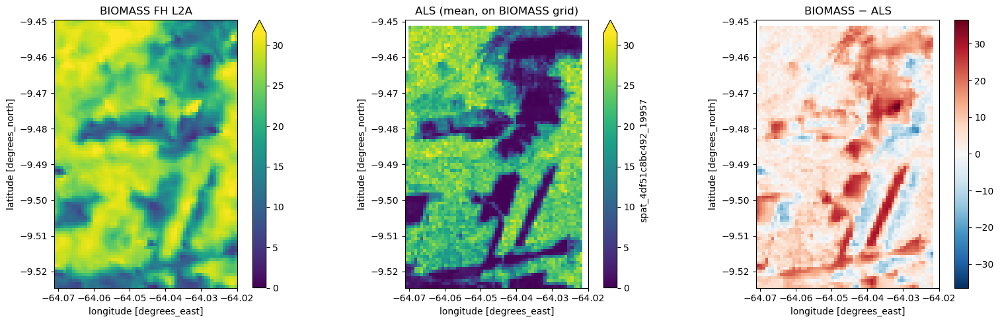

  [figure] outputs/figures/07a_single_tile_maps.png
Log panels: dropped 0 pixels with ALS or FH ≤ 0 m
Single tile log-log fit: ln(FH) = 2.866 + 0.089·ln(ALS)  ->  FH = 18.500·ALS^0.089   R²(log) = 0.125


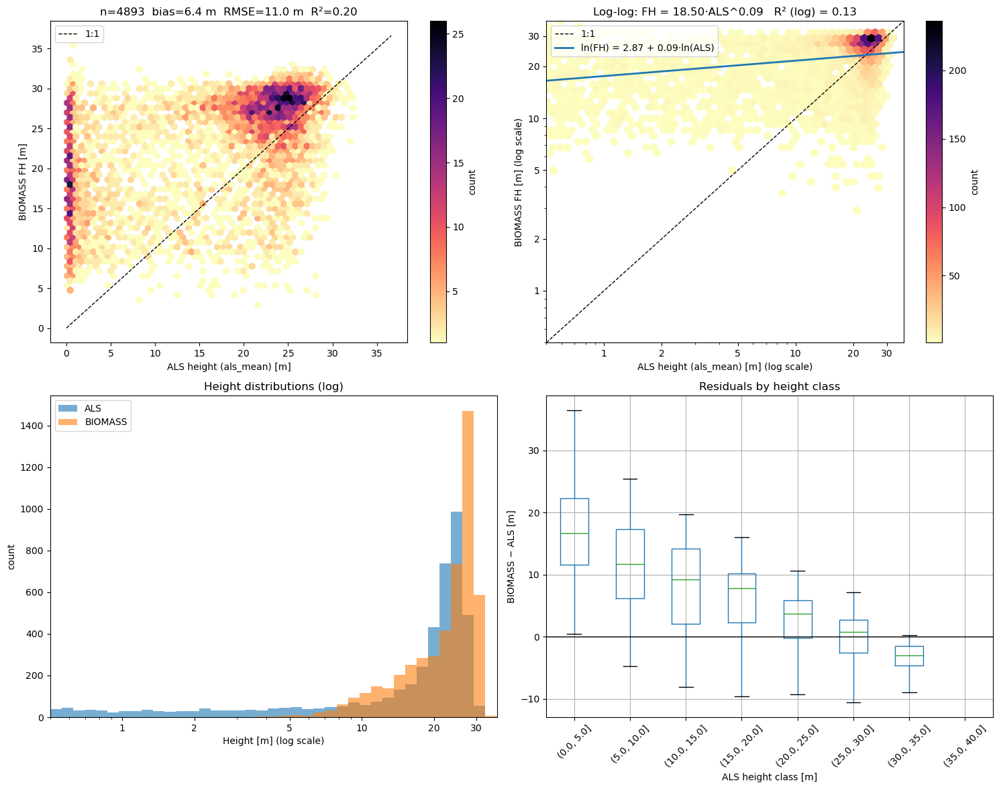

  [figure] outputs/figures/07b_single_tile_scatter_log_hist_resid.png


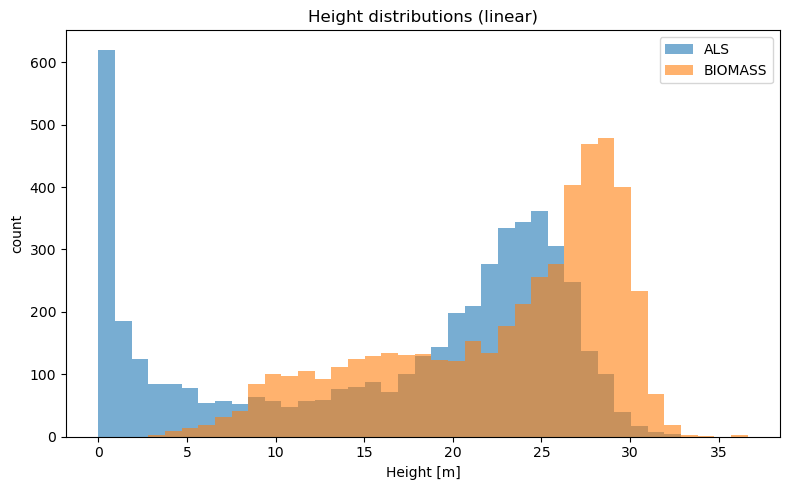

  [figure] outputs/figures/07c_single_tile_hist_linear.png


In [10]:
with section("6-7. Single tile (largest overlap): ALS mean on the BIOMASS grid"):
    best = best_pairs.iloc[0]
    rep(f"Using pair: {best['id_als']}  +  {best['id_fh']}  ({best['dt_days']} days apart)")
    cmp, g1 = compare_pair(als_by_id[best["id_als"]], fh_by_id[best["id_fh"]], return_grids=True)
    fh, als_on_fh_mean = g1["fh"], g1["als_mean"]
    rep(f"Matched BIOMASS pixels with >={MIN_COVER:.0%} ALS coverage: {len(cmp)}")
    rep_table("Single tile: BIOMASS FH vs ALS mean / max",
              pd.DataFrame({k: stats(cmp[k], cmp["fh"]) for k in ["als_mean", "als_max"]}).T,
              "07_single_tile_stats")

    # 7a. maps
    fig, ax = plt.subplots(1, 3, figsize=(16, 5))
    vmax = float(np.nanpercentile(fh, 99))
    fh.plot(ax=ax[0], vmin=0, vmax=vmax, cmap="viridis"); ax[0].set_title("BIOMASS FH L2A")
    als_on_fh_mean.plot(ax=ax[1], vmin=0, vmax=vmax, cmap="viridis"); ax[1].set_title("ALS (mean, on BIOMASS grid)")
    (fh - als_on_fh_mean).plot(ax=ax[2], cmap="RdBu_r", center=0); ax[2].set_title("BIOMASS − ALS")
    for a in ax:
        a.set_aspect("equal")
    plt.tight_layout(); save(fig, "07a_single_tile_maps")

    # 7b. scatter (linear + log-log), log histogram, residuals by height class
    ref = REF
    lim = max(cmp[ref].max(), cmp["fh"].max())
    fig, ax = plt.subplots(2, 2, figsize=(15, 12)); ax = ax.ravel()
    hb = ax[0].hexbin(cmp[ref], cmp["fh"], gridsize=50, mincnt=1, cmap="magma_r")
    ax[0].plot([0, lim], [0, lim], "k--", lw=1, label="1:1")
    ax[0].set_xlabel(f"ALS height ({ref}) [m]"); ax[0].set_ylabel("BIOMASS FH [m]")
    s = stats(cmp[ref], cmp["fh"])
    ax[0].set_title(f"n={s['n']}  bias={s['bias']:.1f} m  RMSE={s['RMSE']:.1f} m  R²={s['R2']:.2f}")
    ax[0].legend(loc="upper left"); plt.colorbar(hb, ax=ax[0], label="count")

    pos = cmp[(cmp[ref] > 0) & (cmp["fh"] > 0)]
    rep(f"Log panels: dropped {len(cmp) - len(pos)} pixels with ALS or FH ≤ 0 m")
    lx, ly = np.log(pos[ref].values), np.log(pos["fh"].values)
    b_log, a_log = np.polyfit(lx, ly, 1)
    res_log = ly - (a_log + b_log * lx)
    r2_log = 1 - np.sum(res_log ** 2) / np.sum((ly - ly.mean()) ** 2)
    a_pow = np.exp(a_log) * np.mean(np.exp(res_log))
    rep(f"Single tile log-log fit: ln(FH) = {a_log:.3f} + {b_log:.3f}·ln(ALS)  ->  FH = {a_pow:.3f}·ALS^{b_log:.3f}"
        f"   R²(log) = {r2_log:.3f}")
    lo = max(0.5, float(np.nanpercentile(np.concatenate([pos[ref], pos["fh"]]), 0.5)))
    hb = ax[1].hexbin(pos[ref], pos["fh"], gridsize=50, mincnt=1, cmap="magma_r", xscale="log", yscale="log",
                      extent=(np.log10(lo), np.log10(lim), np.log10(lo), np.log10(lim)))
    xx = np.geomspace(lo, lim, 100)
    ax[1].plot([lo, lim], [lo, lim], "k--", lw=1, label="1:1")
    ax[1].plot(xx, np.exp(a_log) * xx ** b_log, color="tab:blue", lw=2,
               label=f"ln(FH) = {a_log:.2f} + {b_log:.2f}·ln(ALS)")
    ax[1].set_xlim(lo, lim); ax[1].set_ylim(lo, lim); log_ticks(ax[1], lo, lim)
    ax[1].set_xlabel(f"ALS height ({ref}) [m] (log scale)"); ax[1].set_ylabel("BIOMASS FH [m] (log scale)")
    ax[1].set_title(f"Log-log: FH = {a_pow:.2f}·ALS^{b_log:.2f}   R² (log) = {r2_log:.2f}")
    ax[1].legend(loc="upper left"); plt.colorbar(hb, ax=ax[1], label="count")

    bins = np.geomspace(lo, lim, 40)
    ax[2].hist(pos[ref], bins=bins, alpha=0.6, label="ALS")
    ax[2].hist(pos["fh"], bins=bins, alpha=0.6, label="BIOMASS")
    ax[2].set_xscale("log"); ax[2].set_xlim(lo, lim); log_ticks(ax[2], lo, lim, y=False)
    ax[2].set_xlabel("Height [m] (log scale)"); ax[2].set_ylabel("count")
    ax[2].set_title("Height distributions (log)"); ax[2].legend()

    cmp["h_class"] = pd.cut(cmp[ref], bins=np.arange(0, lim + 5, 5))
    cmp["resid"] = cmp["fh"] - cmp[ref]
    cmp.boxplot(column="resid", by="h_class", ax=ax[3], rot=45, showfliers=False)
    ax[3].axhline(0, color="k", lw=1)
    ax[3].set_xlabel("ALS height class [m]"); ax[3].set_ylabel("BIOMASS − ALS [m]")
    ax[3].set_title("Residuals by height class"); fig.suptitle("")
    plt.tight_layout(); save(fig, "07b_single_tile_scatter_log_hist_resid")

    # 7c. linear-scale histogram (same tile)
    fig, ax = plt.subplots(figsize=(8, 5))
    b_lin = np.linspace(0, lim, 40)
    ax.hist(cmp[ref], bins=b_lin, alpha=0.6, label="ALS"); ax.hist(cmp["fh"], bins=b_lin, alpha=0.6, label="BIOMASS")
    ax.set_xlabel("Height [m]"); ax.set_ylabel("count"); ax.set_title("Height distributions (linear)"); ax.legend()
    plt.tight_layout(); save(fig, "07c_single_tile_hist_linear")

### 8. All tiles

In [11]:
with section("8. All tiles: extraction (parallel, cached in cache_tiles/)", critical=True):
    def run_one(p):
        f = CACHE_DIR / f"{''.join(c if c.isalnum() else '_' for c in p.id_als)}.csv"
        if f.exists():
            return pd.read_csv(f), True
        d = compare_pair_density(als_by_id[p.id_als], fh_by_id[p.id_fh])
        d["dt_days"] = p.dt_days
        d.to_csv(f, index=False)
        return d, False

    res_d, failed = [], []
    t0 = dt.datetime.now()
    with ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
        futs = {ex.submit(run_one, p): p.id_als for p in todo.itertuples()}
        for i, fu in enumerate(as_completed(futs), 1):
            try:
                d, cached = fu.result()
                res_d.append(d)
                status = f"{len(d)} px" + (" (cache)" if cached else "")
            except Exception as e:
                failed.append((futs[fu], str(e)[:200]))
                status = f"FAILED: {str(e)[:100]}"
            el = (dt.datetime.now() - t0).total_seconds() / 60
            print(f"  [{i}/{len(futs)}] {futs[fu]}: {status}   ({el:.1f} min)", flush=True)

    dens = pd.concat(res_d, ignore_index=True)
    dens["resid"] = dens["fh"] - dens[REF]
    allpix = dens                                 
    dens.to_csv(DATA_DIR / "als_vs_fh_pixels.csv", index=False)
    rep(f"Pairs processed: {len(res_d)} | failed: {len(failed)} | matched pixels: {len(dens):,}")
    if failed:
        rep_table("Failed tiles", pd.DataFrame(failed, columns=["id_als", "error"]).set_index("id_als"),
                  "08_failed_tiles")
    rep(f"Tiles: {dens['id_als'].nunique()} | sites: {dens['site'].nunique()} | pixels: {len(dens):,}")
    rep_table("Pixel data summary", dens[["fh", REF, "als_max", "als_mean_canopy", "canopy_cover", "als_std"]]
              .describe(), "08_pixel_summary")


8. All tiles: extraction (parallel, cached in cache_tiles/)
  [1/105] ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_BOM-FUTURO_2025_BFT04: 3322 px (cache)   (0.0 min)
  [2/105] ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_AMAPA_2024_AMP04: 3139 px (cache)   (0.0 min)
  [3/105] ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_AMAPA_2025_AMP04: 3139 px (cache)   (0.0 min)
  [4/105] ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_BOM-FUTURO_2025_BFT01: 4893 px (cache)   (0.0 min)
  [5/105] ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_ALTAMIRA_2025_ALT09: 1820 px (cache)   (0.0 min)
  [6/105] ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_ALTAMIRA_2025_ALT03: 2413 px (cache)   (0.0 min)
  [7/105] ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_ALTAMIRA_2024_ALT03: 2409 px (cache)   (0.0 min)
  [8/105] ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_AMAPA_2024_AMP06: 1618 px (cache)   (0.0 min)
  [9/105] ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_AMAPA_2025_AMP08: 1071 px (cache)   (0.0 min)
  [10/105] ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_AMAPA_2025_AMP06: 1619 px (cache)   (0.0 min)

/tmp/ipykernel_611/4144465657.py:26: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  dens = pd.concat(res_d, ignore_index=True)


Pairs processed: 105 | failed: 0 | matched pixels: 67,181
Tiles: 102 | sites: 1 | pixels: 67,181

--- Pixel data summary ---
             fh  als_mean   als_max  als_mean_canopy  canopy_cover   als_std
count  67181.00  67181.00  67181.00         67015.00      67181.00  67181.00
mean      23.48     23.83     46.21            24.71          0.94      8.48
std        7.52      7.33      9.83             6.27          0.17      2.32
min        0.00      0.02      1.77             5.03          0.00      0.08
25%       19.68     19.74     41.24            20.54          0.96      7.18
50%       25.79     24.13     45.88            24.57          0.99      8.44
75%       28.92     28.83     51.00            29.18          1.00      9.86
max       41.34     47.88     87.86            48.20          1.00     22.66


In [12]:
with section("8b. Overall agreement and per-tile statistics"):
    rep_table("Overall agreement (all pixels)", pd.Series(stats(allpix[REF], allpix["fh"])).to_frame("value"))
    tile = (allpix.groupby("id_als")[[REF, "fh", "lon", "lat", "dt_days"]]
            .apply(lambda g: pd.Series({**stats(g[REF], g["fh"]), "lon": g["lon"].mean(), "lat": g["lat"].mean(),
                                        "als_height": g[REF].mean(), "dt_days": g["dt_days"].iloc[0]}))
            .reset_index())
    tile = tile[tile["n"] >= 10]
    rep_table("Per tile statistics (sorted by RMSE, tiles with >= 10 pixels)",
              tile.sort_values("RMSE").set_index("id_als"), "08_tile_stats")


8b. Overall agreement and per-tile statistics

--- Overall agreement (all pixels) ---
               value
n           67181.00
bias           -0.35
RMSE           10.14
rel_RMSE_%     42.53
R2              0.00

--- Per tile statistics (sorted by RMSE, tiles with >= 10 pixels) ---
                                                                   n   bias   RMSE  rel_RMSE_%    R2    lon   lat  als_height  dt_days
id_als                                                                                                                                
ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_SARACA-TAQUERA_2025_ST17    65.0   0.62   2.04        8.36  0.04 -56.60 -1.70       24.45    462.0
ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_SARACA-TAQUERA_2025_ST18    58.0   1.17   2.26        9.00  0.02 -56.63 -1.71       25.08    462.0
ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_AMAPA_2025_AMP02           180.0   0.54   2.42        8.10  0.01 -51.45  1.51       29.89    194.0
ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_SARAC


8c. Scatter all pixels (ALS ≥ 1 m): linear and log-log fit
Removed 1,114 pixels with ALS < 1.0 m (1.7%), kept 66,067

--- Agreement, ALS ≥ 1 m ---
               value
n           66067.00
bias           -0.58
RMSE           10.01
rel_RMSE_%     41.32
R2              0.00

--- Regression fits (R2/RMSE in metres) ---
                                    a      b     R2   RMSE  R2_log_space
Linear: FH = a + b·ALS         23.569  0.003  0.000  7.407           NaN
Power (log-log): FH = a·ALS^b  18.465  0.079  0.011  7.367         0.003


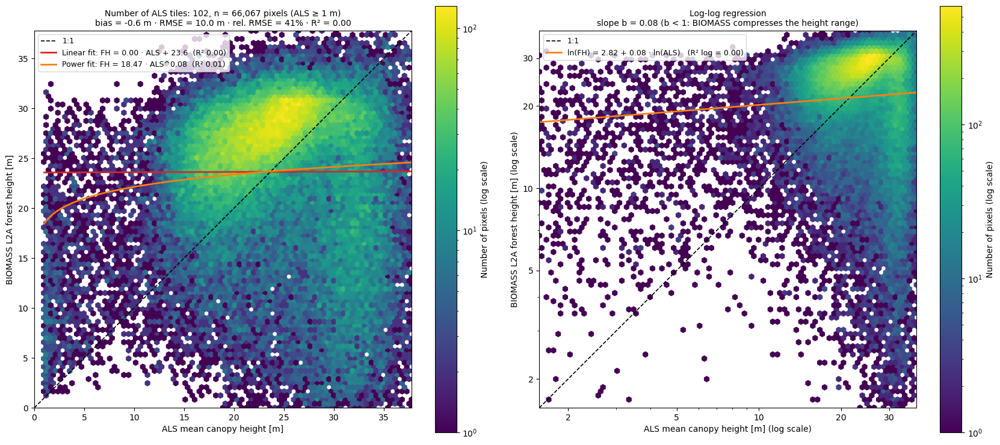

  [figure] outputs/figures/08c_scatter_linear_and_loglog.png
BIOMASS FH maximum: 41.3 m | pixels within 0.5 m of the maximum: 0.0%


In [13]:
with section(f"8c. Scatter all pixels (ALS ≥ {MIN_ALS_H:g} m): linear and log-log fit"):
    x, y = allpix[REF].values, allpix["fh"].values
    ok = np.isfinite(x) & np.isfinite(y)
    n_before = ok.sum()
    ok &= x >= MIN_ALS_H
    rep(f"Removed {n_before - ok.sum():,} pixels with ALS < {MIN_ALS_H} m "
        f"({100 * (n_before - ok.sum()) / n_before:.1f}%), kept {ok.sum():,}")
    n_zero = (ok & (y <= 0)).sum()
    ok &= y > 0
    if n_zero:
        rep(f"Removed {n_zero:,} more pixels with BIOMASS FH ≤ 0 m (needed for the log fit)")
    x, y = x[ok], y[ok]
    s = stats(pd.Series(x), pd.Series(y))
    slope, intercept = np.polyfit(x, y, 1)
    pred_lin = intercept + slope * x
    lx, ly = np.log(x), np.log(y)
    b_log, a_log = np.polyfit(lx, ly, 1)
    res_log = ly - (a_log + b_log * lx)
    r2_log = 1 - np.sum(res_log ** 2) / np.sum((ly - ly.mean()) ** 2)
    a_pow = np.exp(a_log) * np.mean(np.exp(res_log))       # Duan smearing correction
    pred_pow = a_pow * x ** b_log

    def fit_metrics(pred):
        r = y - pred
        return {"R2": 1 - np.sum(r ** 2) / np.sum((y - y.mean()) ** 2), "RMSE": np.sqrt(np.mean(r ** 2))}

    fits = pd.DataFrame({
        "Linear: FH = a + b·ALS": {"a": intercept, "b": slope, **fit_metrics(pred_lin), "R2_log_space": np.nan},
        "Power (log-log): FH = a·ALS^b": {"a": a_pow, "b": b_log, **fit_metrics(pred_pow), "R2_log_space": r2_log},
    }).T
    rep_table(f"Agreement, ALS ≥ {MIN_ALS_H:g} m", pd.Series(s).to_frame("value"))
    rep_table("Regression fits (R2/RMSE in metres)", fits, "08c_regression_fits", nd=3)

    lim = float(np.nanpercentile(np.concatenate([x, y]), 99.5))
    xx = np.linspace(MIN_ALS_H, lim, 200)
    title = (f"Number of ALS tiles: {allpix['id_als'].nunique()}, n = {s['n']:,} pixels (ALS ≥ {MIN_ALS_H:g} m)\n"
             f"bias = {s['bias']:.1f} m · RMSE = {s['RMSE']:.1f} m · "
             f"rel. RMSE = {s['rel_RMSE_%']:.0f}% · R² = {s['R2']:.2f}")
    fig, ax = plt.subplots(1, 2, figsize=(17, 7.5))
    hb = ax[0].hexbin(x, y, gridsize=80, mincnt=1, cmap="viridis", norm=LogNorm(), extent=(0, lim, 0, lim))
    plt.colorbar(hb, ax=ax[0], label="Number of pixels (log scale)")
    ax[0].plot([0, lim], [0, lim], "k--", lw=1.2, label="1:1")
    ax[0].plot(xx, slope * xx + intercept, color="tab:red", lw=2,
               label=f"Linear fit: FH = {slope:.2f} · ALS + {intercept:.1f}  (R² {fits.iloc[0]['R2']:.2f})")
    ax[0].plot(xx, a_pow * xx ** b_log, color="tab:orange", lw=2,
               label=f"Power fit: FH = {a_pow:.2f} · ALS^{b_log:.2f}  (R² {fits.iloc[1]['R2']:.2f})")
    ax[0].set_xlim(0, lim); ax[0].set_ylim(0, lim); ax[0].set_aspect("equal")
    ax[0].set_xlabel("ALS mean canopy height [m]"); ax[0].set_ylabel("BIOMASS L2A forest height [m]")
    ax[0].set_title(title, fontsize=10); ax[0].legend(loc="upper left", fontsize=9)

    lo = max(MIN_ALS_H, float(np.nanpercentile(np.concatenate([x, y]), 0.5)))
    hb = ax[1].hexbin(x, y, gridsize=80, mincnt=1, cmap="viridis", norm=LogNorm(), xscale="log", yscale="log",
                      extent=(np.log10(lo), np.log10(lim), np.log10(lo), np.log10(lim)))
    plt.colorbar(hb, ax=ax[1], label="Number of pixels (log scale)")
    ax[1].plot([lo, lim], [lo, lim], "k--", lw=1.2, label="1:1")
    ax[1].plot(xx, np.exp(a_log) * xx ** b_log, color="tab:orange", lw=2,
               label=f"ln(FH) = {a_log:.2f} + {b_log:.2f} · ln(ALS)   (R² log = {r2_log:.2f})")
    ax[1].set_xlim(lo, lim); ax[1].set_ylim(lo, lim); ax[1].set_aspect("equal")
    ax[1].set_xlabel("ALS mean canopy height [m] (log scale)")
    ax[1].set_ylabel("BIOMASS L2A forest height [m] (log scale)")
    note = "b < 1: BIOMASS compresses the height range" if b_log < 1 else "b > 1: BIOMASS stretches the height range"
    ax[1].set_title(f"Log-log regression\nslope b = {b_log:.2f} ({note})", fontsize=10)
    log_ticks(ax[1], lo, lim); ax[1].legend(loc="upper left", fontsize=9)
    plt.tight_layout(); save(fig, "08c_scatter_linear_and_loglog")

    # BIOMASS saturation check
    fh_max = float(np.nanmax(allpix["fh"]))
    rep(f"BIOMASS FH maximum: {fh_max:.1f} m | pixels within 0.5 m of the maximum: "
        f"{100 * np.mean(allpix['fh'] >= fh_max - 0.5):.1f}%")

### 9. MAPS


9a-b. Maps of bias and RMSE


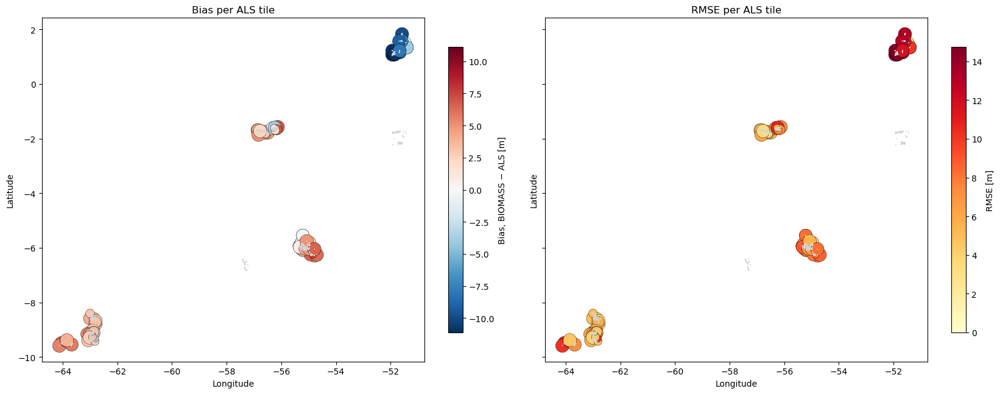

  [figure] outputs/figures/09a_map_bias_rmse_per_tile.png


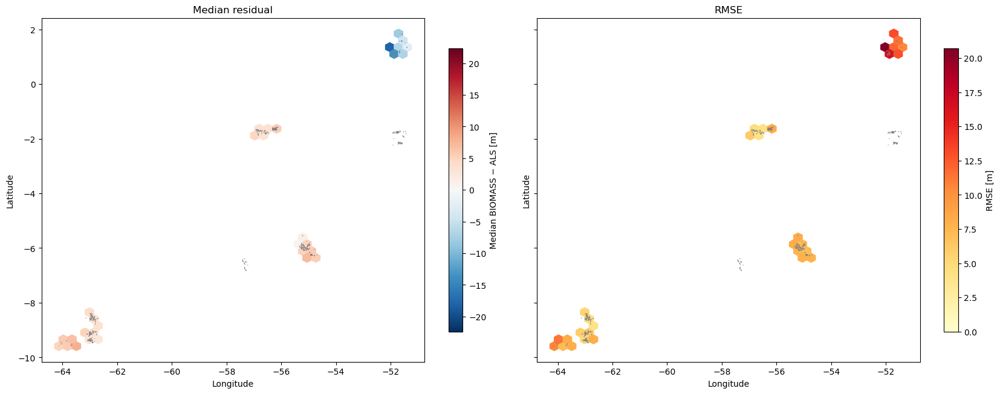

  [figure] outputs/figures/09b_map_residual_grid.png


In [14]:
with section("9a-b. Maps of bias and RMSE"):
    blim = np.nanpercentile(np.abs(tile["bias"]), 95)
    size = np.clip(tile["n"], 20, 250)
    fig, ax = plt.subplots(1, 2, figsize=(17, 7), sharex=True, sharey=True)
    for a in ax:
        gdf_als.boundary.plot(ax=a, color="lightgrey", lw=0.5)
        a.set_xlabel("Longitude"); a.set_ylabel("Latitude"); a.set_aspect("equal")
    sc = ax[0].scatter(tile["lon"], tile["lat"], c=tile["bias"], cmap="RdBu_r", vmin=-blim, vmax=blim,
                       s=size, edgecolor="k", lw=0.3)
    plt.colorbar(sc, ax=ax[0], shrink=0.7, label="Bias, BIOMASS − ALS [m]"); ax[0].set_title("Bias per ALS tile")
    sc = ax[1].scatter(tile["lon"], tile["lat"], c=tile["RMSE"], cmap="YlOrRd", vmin=0,
                       vmax=np.nanpercentile(tile["RMSE"], 95), s=size, edgecolor="k", lw=0.3)
    plt.colorbar(sc, ax=ax[1], shrink=0.7, label="RMSE [m]"); ax[1].set_title("RMSE per ALS tile")
    plt.tight_layout(); save(fig, "09a_map_bias_rmse_per_tile")

    GRID = 40
    rlim = np.nanpercentile(np.abs(allpix["resid"]), 95)
    fig, ax = plt.subplots(1, 2, figsize=(17, 7), sharex=True, sharey=True)
    hb = ax[0].hexbin(allpix["lon"], allpix["lat"], C=allpix["resid"], reduce_C_function=np.median,
                      gridsize=GRID, mincnt=5, cmap="RdBu_r", vmin=-rlim, vmax=rlim)
    plt.colorbar(hb, ax=ax[0], shrink=0.7, label="Median BIOMASS − ALS [m]"); ax[0].set_title("Median residual")
    hb = ax[1].hexbin(allpix["lon"], allpix["lat"], C=allpix["resid"],
                      reduce_C_function=lambda v: np.sqrt(np.mean(np.square(v))),
                      gridsize=GRID, mincnt=5, cmap="YlOrRd", vmin=0)
    plt.colorbar(hb, ax=ax[1], shrink=0.7, label="RMSE [m]"); ax[1].set_title("RMSE")
    for a in ax:
        gdf_als.boundary.plot(ax=a, color="grey", lw=0.3)
        a.set_xlabel("Longitude"); a.set_ylabel("Latitude"); a.set_aspect("equal")
    plt.tight_layout(); save(fig, "09b_map_residual_grid")

In [15]:
with section("9c. Interactive map of tile statistics"):
    norm = mcolors.TwoSlopeNorm(vmin=-blim, vcenter=0, vmax=blim)
    m = folium.Map(location=[tile["lat"].mean(), tile["lon"].mean()], zoom_start=6, tiles="Esri.WorldImagery")
    for _, t in tile.iterrows():
        folium.CircleMarker(
            location=[t["lat"], t["lon"]], radius=4 + 8 * min(t["n"], 250) / 250,
            color="black", weight=0.5, fill=True, fill_opacity=0.9,
            fill_color=mcolors.to_hex(cm.RdBu_r(norm(np.clip(t["bias"], -blim, blim)))),
            tooltip=(f"{t['id_als']}<br>bias {t['bias']:.1f} m · RMSE {t['RMSE']:.1f} m · "
                     f"R² {t['R2']:.2f}<br>n = {int(t['n'])} · ALS height {t['als_height']:.1f} m · "
                     f"gap {int(t['dt_days'])} days"),
        ).add_to(m)
    m.save(MAP_DIR / "09c_tile_stats.html"); rep(f"  [map] {MAP_DIR / '09c_tile_stats.html'}")
    display(m)


9c. Interactive map of tile statistics
  [map] outputs/maps/09c_tile_stats.html



9d. Best and worst matching tiles, pixel by pixel
Best tile:  ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_SARACA-TAQUERA_2025_ST17  RMSE 2.0 m, bias 0.6 m
Worst tile: ALS_CHM_BR_SAM_PROCESSED_SFB_AMAZON_AMAPA_2025_AMP08  RMSE 19.8 m, bias -17.9 m


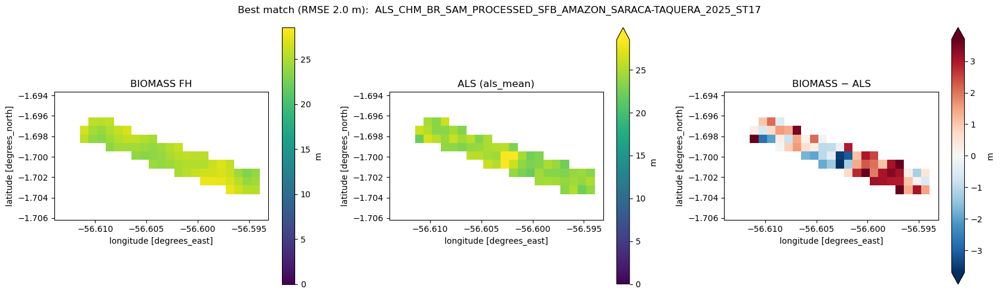

  [figure] outputs/figures/09d_best_tile.png


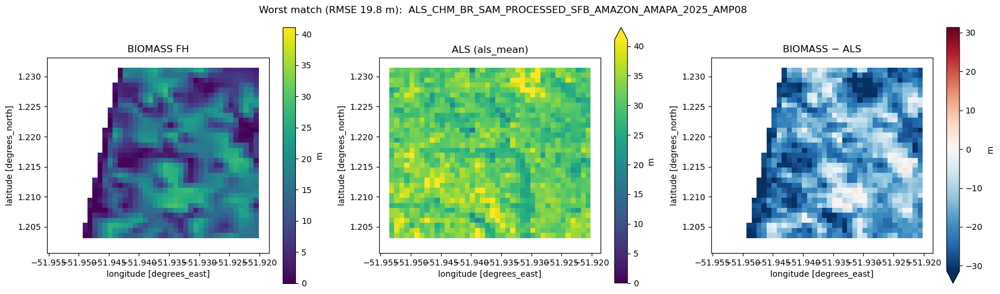

  [figure] outputs/figures/09d_worst_tile.png


In [16]:
with section("9d. Best and worst matching tiles, pixel by pixel"):
    def plot_tile(id_als, title, name):
        p_ = best_pairs.set_index("id_als").loc[id_als]
        _, g = compare_pair(als_by_id[id_als], fh_by_id[p_["id_fh"]], return_grids=True)
        ref_g = g[REF].where(g["cover"] >= MIN_COVER)
        fh_t = g["fh"].where(ref_g.notnull())
        vmax = float(np.nanpercentile(np.concatenate([fh_t.values.ravel(), ref_g.values.ravel()]), 99))
        dlim = float(np.nanpercentile(np.abs((fh_t - ref_g).values), 95))
        fig, ax = plt.subplots(1, 3, figsize=(17, 5))
        fh_t.plot(ax=ax[0], vmin=0, vmax=vmax, cmap="viridis", cbar_kwargs={"label": "m"})
        ref_g.plot(ax=ax[1], vmin=0, vmax=vmax, cmap="viridis", cbar_kwargs={"label": "m"})
        (fh_t - ref_g).plot(ax=ax[2], cmap="RdBu_r", vmin=-dlim, vmax=dlim, cbar_kwargs={"label": "m"})
        for a, t in zip(ax, ["BIOMASS FH", f"ALS ({REF})", "BIOMASS − ALS"]):
            a.set_title(t); a.set_aspect("equal")
        fig.suptitle(f"{title}  {id_als}")
        plt.tight_layout(); save(fig, name)

    srt = tile.sort_values("RMSE")
    good, bad = srt.iloc[0], srt.iloc[-1]
    rep(f"Best tile:  {good['id_als']}  RMSE {good['RMSE']:.1f} m, bias {good['bias']:.1f} m")
    rep(f"Worst tile: {bad['id_als']}  RMSE {bad['RMSE']:.1f} m, bias {bad['bias']:.1f} m")
    plot_tile(good["id_als"], f"Best match (RMSE {good['RMSE']:.1f} m):", "09d_best_tile")
    plot_tile(bad["id_als"], f"Worst match (RMSE {bad['RMSE']:.1f} m):", "09d_worst_tile")

### 10. what drives the difference?


10. What drives the differences? (height, time gap, quality layer)


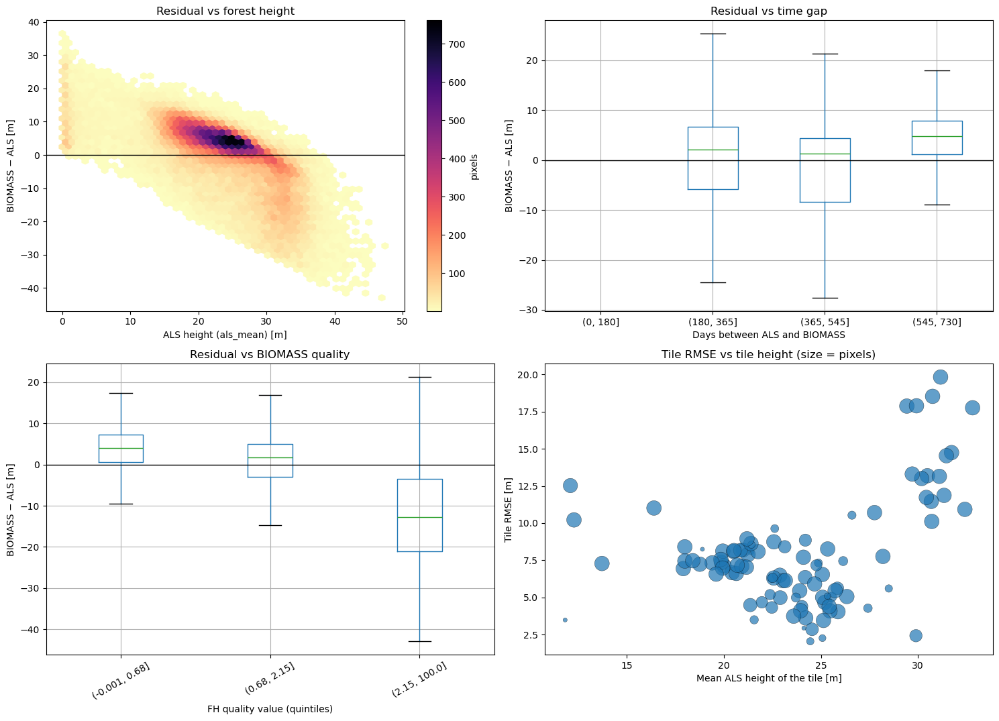

  [figure] outputs/figures/10_drivers.png

--- Stats by time gap class ---
                  n  bias   RMSE  rel_RMSE_%    R2
(180, 365]  32469.0 -0.32  10.78       47.58  0.02
(365, 545]  22486.0 -2.70  10.48       38.42  0.06
(545, 730]  12226.0  3.90   7.33       35.57  0.03

--- Stats by quality class ---
                      n   bias   RMSE  rel_RMSE_%    R2
(-0.001, 0.68]  40309.0   3.21   7.96       35.28  0.00
(0.68, 2.15]    13437.0   0.61   6.96       25.84  0.12
(2.15, 100.0]   13435.0 -11.99  16.59       67.53  0.02


In [17]:
with section("10. What drives the differences? (height, time gap, quality layer)"):
    fig, ax = plt.subplots(2, 2, figsize=(15, 11))
    hb = ax[0, 0].hexbin(allpix[REF], allpix["resid"], gridsize=50, mincnt=1, cmap="magma_r")
    ax[0, 0].axhline(0, color="k", lw=1)
    ax[0, 0].set_xlabel(f"ALS height ({REF}) [m]"); ax[0, 0].set_ylabel("BIOMASS − ALS [m]")
    ax[0, 0].set_title("Residual vs forest height"); plt.colorbar(hb, ax=ax[0, 0], label="pixels")

    allpix["gap_class"] = pd.cut(allpix["dt_days"].abs(), bins=[0, 180, 365, 545, 730])
    allpix.boxplot(column="resid", by="gap_class", ax=ax[0, 1], showfliers=False)
    ax[0, 1].axhline(0, color="k", lw=1)
    ax[0, 1].set_xlabel("Days between ALS and BIOMASS"); ax[0, 1].set_ylabel("BIOMASS − ALS [m]")
    ax[0, 1].set_title("Residual vs time gap")

    allpix["q_class"] = pd.qcut(allpix["fh_quality"], q=5, duplicates="drop")
    allpix.boxplot(column="resid", by="q_class", ax=ax[1, 0], showfliers=False, rot=30)
    ax[1, 0].axhline(0, color="k", lw=1)
    ax[1, 0].set_xlabel("FH quality value (quintiles)"); ax[1, 0].set_ylabel("BIOMASS − ALS [m]")
    ax[1, 0].set_title("Residual vs BIOMASS quality")

    ax[1, 1].scatter(tile["als_height"], tile["RMSE"], s=np.clip(tile["n"], 20, 250),
                     color="tab:blue", alpha=0.7, edgecolor="k", lw=0.3)
    ax[1, 1].set_xlabel("Mean ALS height of the tile [m]"); ax[1, 1].set_ylabel("Tile RMSE [m]")
    ax[1, 1].set_title("Tile RMSE vs tile height (size = pixels)")
    fig.suptitle(""); plt.tight_layout(); save(fig, "10_drivers")

    rep_table("Stats by time gap class",
              pd.DataFrame({str(q): stats(g[REF], g["fh"]) for q, g in allpix.groupby("gap_class", observed=True)}).T,
              "10_stats_by_time_gap")
    rep_table("Stats by quality class",
              pd.DataFrame({str(q): stats(g[REF], g["fh"]) for q, g in allpix.groupby("q_class", observed=True)}).T,
              "10_stats_by_quality")

### 11. Explore results with forest covers

In [18]:
COVER_BINS = [0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0001]
COVER_LABELS = ["<10%", "10–30%", "30–50%", "50–70%", "70–90%", ">90%"]
H_BINS = [0, 5, 10, 15, 20, 25, 30, 40, np.inf]
H_LABELS = ["0–5", "5–10", "10–15", "15–20", "20–25", "25–30", "30–40", ">40"]


def table_by(df, col, ref=REF, min_n=30):
    t = pd.DataFrame({str(k): vstats(g[ref], g["fh"]) for k, g in df.groupby(col, observed=True)}).T
    return t[t["n"] >= min_n]

In [19]:
with section(f"11b. Validation metrics by canopy cover class (cover = ALS cells > {CANOPY_HT:g} m)"):
    dens["cover_class"] = pd.cut(dens["canopy_cover"], COVER_BINS, labels=COVER_LABELS, right=False)
    dens["h_class"] = pd.cut(dens[REF], H_BINS, labels=H_LABELS, right=False)
    dens["std_class"] = pd.qcut(dens["als_std"], 5, duplicates="drop")
    cover_tab = table_by(dens, "cover_class")
    rep_table("Metrics by canopy cover class", cover_tab, "11b_metrics_by_canopy_cover")


11b. Validation metrics by canopy cover class (cover = ALS cells > 5 m)

--- Metrics by canopy cover class ---
              n  ALS_mean  FH_mean   bias  median_resid    MAE   RMSE  ubRMSE  NMAD  rel_RMSE_%    R2   CCC  slope  intercept  within_5m_%  within_10m_%
<10%     1566.0      0.80    13.40  12.60         11.39  12.60  14.94    8.03  9.34     1871.73  0.02 -0.01  -1.84      14.87        21.84         43.42
10–30%    521.0      3.16    15.56  12.41         11.64  12.42  14.40    7.32  8.68      456.57  0.00  0.00   0.14      15.12        18.04         42.03
30–50%    411.0      6.10    17.10  11.00         10.88  11.12  12.98    6.90  7.81      212.64  0.05  0.03   0.96      11.21        21.41         45.74
50–70%    502.0      9.95    18.15   8.20          8.28   9.20  10.96    7.28  8.02      110.17  0.03  0.05   0.49      13.30        30.08         56.77
70–90%   4290.0     16.74    22.43   5.69          7.37   8.38   9.55    7.68  5.77       57.06  0.00  0.03   0.11      20.


11c. Residuals and metrics per canopy cover class


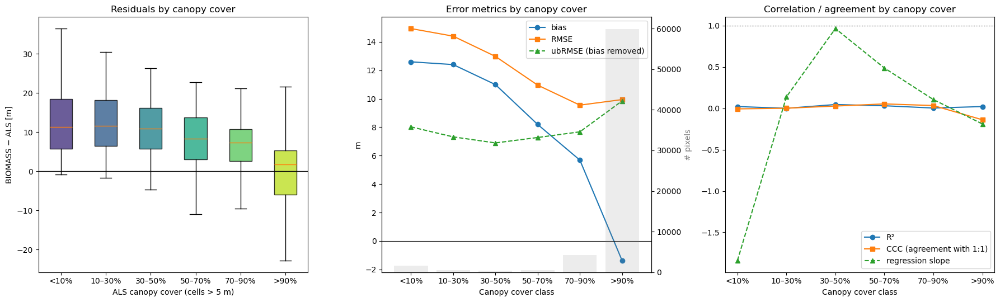

  [figure] outputs/figures/11c_metrics_by_canopy_cover.png


In [20]:
with section("11c. Residuals and metrics per canopy cover class"):
    cols = plt.cm.viridis(np.linspace(0.15, 0.9, len(COVER_LABELS)))
    groups = [dens.loc[dens["cover_class"] == c, "resid"].dropna() for c in COVER_LABELS]
    fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
    bp = ax[0].boxplot(groups, showfliers=False, patch_artist=True)
    ax[0].set_xticks(range(1, len(COVER_LABELS) + 1), COVER_LABELS)
    for patch, c in zip(bp["boxes"], cols):
        patch.set_facecolor(c); patch.set_alpha(0.8)
    ax[0].axhline(0, color="k", lw=1)
    ax[0].set_xlabel(f"ALS canopy cover (cells > {CANOPY_HT:g} m)"); ax[0].set_ylabel("BIOMASS − ALS [m]")
    ax[0].set_title("Residuals by canopy cover")
    xc = np.arange(len(cover_tab))
    ax[1].plot(xc, cover_tab["bias"], "o-", label="bias")
    ax[1].plot(xc, cover_tab["RMSE"], "s-", label="RMSE")
    ax[1].plot(xc, cover_tab["ubRMSE"], "^--", label="ubRMSE (bias removed)")
    ax[1].axhline(0, color="k", lw=0.8)
    ax[1].set_xticks(xc, cover_tab.index); ax[1].set_ylabel("m")
    ax[1].set_xlabel("Canopy cover class"); ax[1].set_title("Error metrics by canopy cover"); ax[1].legend()
    a2 = ax[1].twinx(); a2.bar(xc, cover_tab["n"], alpha=0.15, color="grey"); a2.set_ylabel("# pixels", color="grey")
    ax[2].plot(xc, cover_tab["R2"], "o-", label="R²")
    ax[2].plot(xc, cover_tab["CCC"], "s-", label="CCC (agreement with 1:1)")
    ax[2].plot(xc, cover_tab["slope"], "^--", label="regression slope")
    ax[2].axhline(1, color="k", lw=0.8, ls=":")
    ax[2].set_xticks(xc, cover_tab.index); ax[2].set_xlabel("Canopy cover class")
    ax[2].set_title("Correlation / agreement by canopy cover"); ax[2].legend()
    plt.tight_layout(); save(fig, "11c_metrics_by_canopy_cover")


11d. Scatter plots per canopy cover class


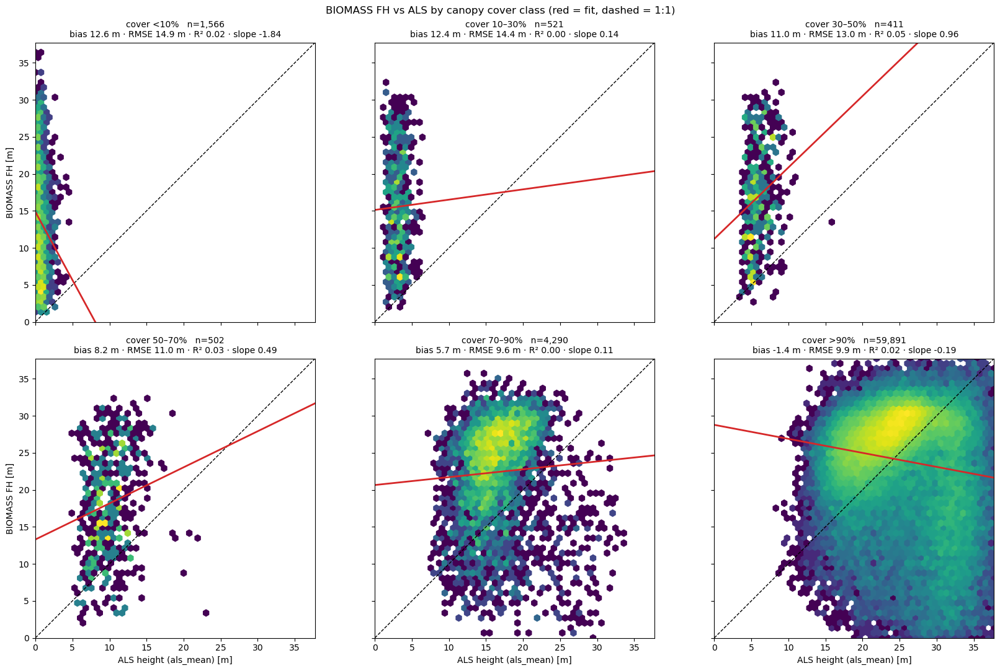

  [figure] outputs/figures/11d_scatter_by_canopy_cover.png


In [21]:
with section("11d. Scatter plots per canopy cover class"):
    lim = float(np.nanpercentile(np.concatenate([dens[REF], dens["fh"]]), 99.5))
    fig, axs = plt.subplots(2, 3, figsize=(17, 11), sharex=True, sharey=True)
    for a, c in zip(axs.ravel(), COVER_LABELS):
        g = dens[dens["cover_class"] == c]
        if len(g) < 30:
            a.set_title(f"cover {c}: n={len(g)} (too few)"); continue
        a.hexbin(g[REF], g["fh"], gridsize=50, mincnt=1, cmap="viridis", norm=LogNorm(), extent=(0, lim, 0, lim))
        s = vstats(g[REF], g["fh"])
        xx = np.array([0, lim])
        a.plot(xx, xx, "k--", lw=1)
        a.plot(xx, s["slope"] * xx + s["intercept"], color="tab:red", lw=2)
        a.set_title(f"cover {c}   n={s['n']:,}\nbias {s['bias']:.1f} m · RMSE {s['RMSE']:.1f} m · "
                    f"R² {s['R2']:.2f} · slope {s['slope']:.2f}", fontsize=10)
        a.set_xlim(0, lim); a.set_ylim(0, lim); a.set_aspect("equal")
    for a in axs[-1]:
        a.set_xlabel(f"ALS height ({REF}) [m]")
    for a in axs[:, 0]:
        a.set_ylabel("BIOMASS FH [m]")
    fig.suptitle("BIOMASS FH vs ALS by canopy cover class (red = fit, dashed = 1:1)")
    plt.tight_layout(); save(fig, "11d_scatter_by_canopy_cover")


11e. Height class × canopy cover class


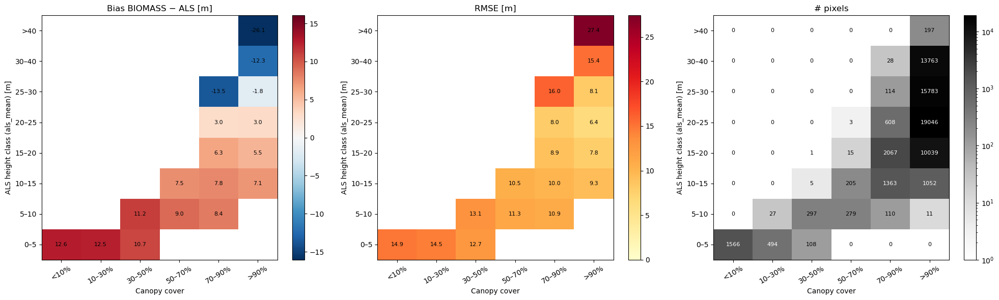

  [figure] outputs/figures/11e_height_x_cover_matrix.png

--- bias by height class (rows) × canopy cover (columns) ---
cover_class  <10%  10–30%  30–50%  50–70%  70–90%   >90%
h_class                                                 
0–5          12.6   12.49   10.67     NaN     NaN    NaN
5–10          NaN   10.89   11.16    9.05    8.36   5.26
10–15         NaN     NaN   11.30    7.46    7.76   7.09
15–20         NaN     NaN   -2.35    6.29    6.34   5.51
20–25         NaN     NaN     NaN  -11.19    2.95   3.02
25–30         NaN     NaN     NaN     NaN  -13.55  -1.82
30–40         NaN     NaN     NaN     NaN  -16.35 -12.29
>40           NaN     NaN     NaN     NaN     NaN -26.06

--- RMSE by height class (rows) × canopy cover (columns) ---
cover_class   <10%  10–30%  30–50%  50–70%  70–90%   >90%
h_class                                                  
0–5          14.94   14.48   12.73     NaN     NaN    NaN
5–10           NaN   13.03   13.11   11.33   10.88   7.21
10–15          Na

In [22]:
with section("11e. Height class × canopy cover class"):
    MIN_N_CELL = 30
    grid = (dens.groupby(["h_class", "cover_class"], observed=False)["resid"]
            .agg(n="size", bias="mean", RMSE=lambda v: np.sqrt(np.mean(v ** 2))))
    fig, ax = plt.subplots(1, 3, figsize=(20, 6))
    for a, (metric, cmap, kw) in zip(ax, [("bias", "RdBu_r", {}), ("RMSE", "YlOrRd", {"vmin": 0}),
                                          ("n", "Greys", {"norm": LogNorm()})]):
        M = grid[metric].unstack("cover_class").reindex(index=H_LABELS, columns=COVER_LABELS)
        N = grid["n"].unstack("cover_class").reindex(index=H_LABELS, columns=COVER_LABELS)
        if metric != "n":
            M = M.where(N >= MIN_N_CELL)
        if metric == "bias":
            v = np.nanpercentile(np.abs(M.values.astype(float)), 95)
            kw = {"vmin": -v, "vmax": v}
        im = a.imshow(M.values.astype(float), cmap=cmap, origin="lower", aspect="auto", **kw)
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                val = M.values[i, j]
                if np.isfinite(val):
                    dark = metric == "n" and val > 0 and im.norm(val) > 0.6
                    a.text(j, i, f"{val:.0f}" if metric == "n" else f"{val:.1f}", ha="center", va="center",
                           fontsize=8, color="white" if dark else "black")
        a.set_xticks(range(len(COVER_LABELS)), COVER_LABELS, rotation=30)
        a.set_yticks(range(len(H_LABELS)), H_LABELS)
        a.set_xlabel("Canopy cover"); a.set_ylabel(f"ALS height class ({REF}) [m]")
        a.set_title({"bias": "Bias BIOMASS − ALS [m]", "RMSE": "RMSE [m]", "n": "# pixels"}[metric])
        plt.colorbar(im, ax=a)
    plt.tight_layout(); save(fig, "11e_height_x_cover_matrix")
    for metric in ("bias", "RMSE", "n"):
        M = grid[metric].unstack("cover_class").reindex(index=H_LABELS, columns=COVER_LABELS)
        rep_table(f"{metric} by height class (rows) × canopy cover (columns)", M, f"11e_matrix_{metric}")


11f. Which ALS metric does BIOMASS represent? (mean / mean of canopy / max)


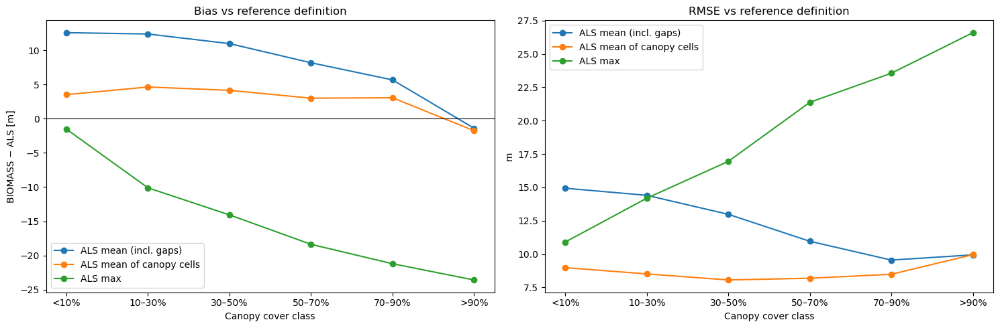

  [figure] outputs/figures/11f_reference_definition.png

--- Bias / RMSE per reference definition and cover class ---
                                n                                                    bias                                                   RMSE                                                     R2                                 
reference   ALS mean (incl. gaps) ALS mean of canopy cells  ALS max ALS mean (incl. gaps) ALS mean of canopy cells ALS max ALS mean (incl. gaps) ALS mean of canopy cells ALS max ALS mean (incl. gaps) ALS mean of canopy cells ALS max
cover_class                                                                                                                                                                                                                             
<10%                       1566.0                   1400.0   1566.0                 12.60                     3.53   -1.53                 14.94                     8.98   10.91      

In [23]:
with section("11f. Which ALS metric does BIOMASS represent? (mean / mean of canopy / max)"):
    ref_cols = {"ALS mean (incl. gaps)": "als_mean", "ALS mean of canopy cells": "als_mean_canopy",
                "ALS max": "als_max"}
    cmp_ref = pd.concat({name: table_by(dens.dropna(subset=[c]), "cover_class", ref=c)[["n", "bias", "RMSE", "R2"]]
                         for name, c in ref_cols.items()}, names=["reference", "cover_class"])
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    for name in ref_cols:
        t = cmp_ref.loc[name]
        ax[0].plot(t.index.astype(str), t["bias"], "o-", label=name)
        ax[1].plot(t.index.astype(str), t["RMSE"], "o-", label=name)
    ax[0].axhline(0, color="k", lw=0.8)
    ax[0].set_title("Bias vs reference definition"); ax[0].set_ylabel("BIOMASS − ALS [m]")
    ax[1].set_title("RMSE vs reference definition"); ax[1].set_ylabel("m")
    for a in ax:
        a.set_xlabel("Canopy cover class"); a.legend()
    plt.tight_layout(); save(fig, "11f_reference_definition")
    rep_table("Bias / RMSE per reference definition and cover class", cmp_ref.unstack("reference"),
              "11f_reference_definition")


11g. Structural heterogeneity and continuous canopy cover


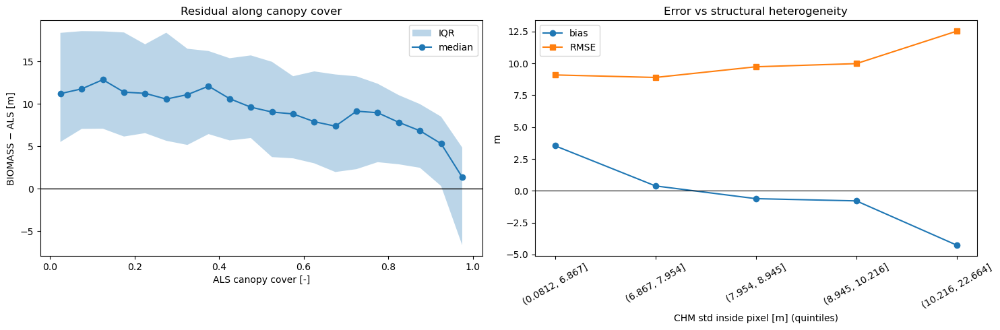

  [figure] outputs/figures/11g_cover_continuous_heterogeneity.png

--- Metrics by CHM std (heterogeneity) quintile ---
                        n  ALS_mean  FH_mean  bias  median_resid   MAE   RMSE  ubRMSE   NMAD  rel_RMSE_%    R2   CCC  slope  intercept  within_5m_%  within_10m_%
(0.0812, 6.867]   13437.0     19.89    23.43  3.54          3.75  6.75   9.10    8.38   4.56       45.74  0.31  0.50   0.45      14.54        51.29         79.58
(6.867, 7.954]    13436.0     24.52    24.91  0.39          2.84  6.74   8.90    8.89   5.66       36.29  0.00 -0.01  -0.01      25.07        48.30         80.34
(7.954, 8.945]    13436.0     24.67    24.06 -0.61          2.18  7.38   9.74    9.72   6.92       39.47  0.01 -0.07  -0.09      26.26        44.65         75.81
(8.945, 10.216]   13436.0     24.31    23.52 -0.79          1.86  7.71   9.98    9.95   7.96       41.07  0.01 -0.08  -0.10      25.89        40.80         73.76
(10.216, 22.664]  13436.0     25.77    21.50 -4.27         -1.54  9.78 

In [24]:
with section("11g. Structural heterogeneity and continuous canopy cover"):
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    cb = pd.cut(dens["canopy_cover"], np.linspace(0, 1, 21), include_lowest=True)
    q = dens.groupby(cb, observed=True)["resid"].quantile([0.25, 0.5, 0.75]).unstack()
    mid = np.array([iv.mid for iv in q.index])
    ax[0].fill_between(mid, q[0.25], q[0.75], alpha=0.3, label="IQR")
    ax[0].plot(mid, q[0.5], "o-", label="median")
    ax[0].axhline(0, color="k", lw=1)
    ax[0].set_xlabel("ALS canopy cover [-]"); ax[0].set_ylabel("BIOMASS − ALS [m]")
    ax[0].set_title("Residual along canopy cover"); ax[0].legend()
    std_tab = table_by(dens, "std_class")
    xs = np.arange(len(std_tab))
    ax[1].plot(xs, std_tab["bias"], "o-", label="bias")
    ax[1].plot(xs, std_tab["RMSE"], "s-", label="RMSE")
    ax[1].axhline(0, color="k", lw=0.8)
    ax[1].set_xticks(xs, std_tab.index, rotation=30)
    ax[1].set_xlabel("CHM std inside pixel [m] (quintiles)"); ax[1].set_ylabel("m")
    ax[1].set_title("Error vs structural heterogeneity"); ax[1].legend()
    plt.tight_layout(); save(fig, "11g_cover_continuous_heterogeneity")
    rep_table("Metrics by CHM std (heterogeneity) quintile", std_tab, "11g_metrics_by_heterogeneity")


11h. Sites (ALS collections) and tiles


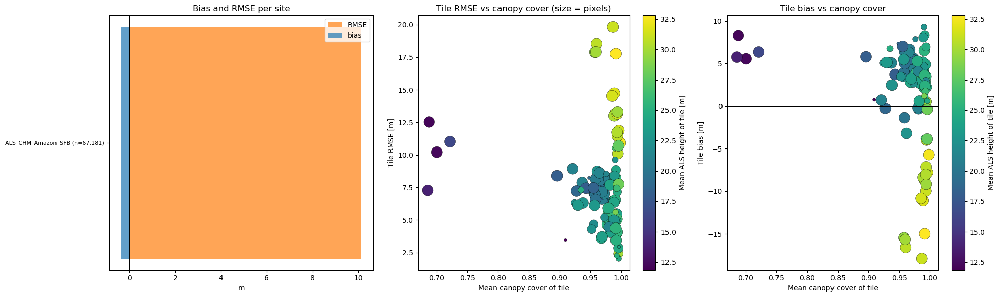

  [figure] outputs/figures/11h_sites_tiles.png

--- Metrics per site ---
                          n  ALS_mean  FH_mean  bias  median_resid   MAE   RMSE  ubRMSE  NMAD  rel_RMSE_%   R2   CCC  slope  intercept  within_5m_%  within_10m_%  canopy_cover  n_tiles
ALS_CHM_Amazon_SFB  67181.0     23.83    23.48 -0.35          2.37  7.67  10.14   10.13  6.97       42.53  0.0  0.07   0.07      21.77        43.64         74.27          0.94      102

--- Metrics per tile (with density) ---
                                                                 n  ALS_mean  FH_mean   bias  median_resid    MAE   RMSE  ubRMSE   NMAD  rel_RMSE_%    R2   CCC  slope  intercept  within_5m_%  within_10m_%  canopy_cover  als_std                site
id_als                                                                                                                                                                                                                                                 
ALS_CHM_BR_SAM_PROCE

In [25]:
with section("11h. Sites (ALS collections) and tiles"):
    site_tab = table_by(dens, "site", min_n=30)
    site_tab["canopy_cover"] = dens.groupby("site")["canopy_cover"].mean()
    site_tab["n_tiles"] = dens.groupby("site")["id_als"].nunique()
    site_tab = site_tab.sort_values("RMSE")
    tile_d = (dens.groupby("id_als")[[REF, "fh", "canopy_cover", "als_std", "site"]]
              .apply(lambda g: pd.Series({**vstats(g[REF], g["fh"]), "canopy_cover": g["canopy_cover"].mean(),
                                          "als_std": g["als_std"].mean(), "site": g["site"].iloc[0]}))
              .reset_index())
    tile_d = tile_d[tile_d["n"] >= 10]

    fig, ax = plt.subplots(1, 3, figsize=(20, 6))
    ys = np.arange(len(site_tab))
    ax[0].barh(ys, site_tab["RMSE"], color="tab:orange", alpha=0.7, label="RMSE")
    ax[0].barh(ys, site_tab["bias"], color="tab:blue", alpha=0.7, label="bias")
    ax[0].set_yticks(ys, [f"{s_} (n={int(n):,})" for s_, n in zip(site_tab.index, site_tab["n"])], fontsize=8)
    ax[0].axvline(0, color="k", lw=0.8); ax[0].set_xlabel("m"); ax[0].legend(); ax[0].set_title("Bias and RMSE per site")
    sc = ax[1].scatter(tile_d["canopy_cover"], tile_d["RMSE"], c=tile_d["ALS_mean"], cmap="viridis",
                       s=np.clip(tile_d["n"], 20, 250), edgecolor="k", lw=0.3)
    plt.colorbar(sc, ax=ax[1], label="Mean ALS height of tile [m]")
    ax[1].set_xlabel("Mean canopy cover of tile"); ax[1].set_ylabel("Tile RMSE [m]")
    ax[1].set_title("Tile RMSE vs canopy cover (size = pixels)")
    sc = ax[2].scatter(tile_d["canopy_cover"], tile_d["bias"], c=tile_d["ALS_mean"], cmap="viridis",
                       s=np.clip(tile_d["n"], 20, 250), edgecolor="k", lw=0.3)
    plt.colorbar(sc, ax=ax[2], label="Mean ALS height of tile [m]")
    ax[2].axhline(0, color="k", lw=0.8)
    ax[2].set_xlabel("Mean canopy cover of tile"); ax[2].set_ylabel("Tile bias [m]")
    ax[2].set_title("Tile bias vs canopy cover")
    plt.tight_layout(); save(fig, "11h_sites_tiles")
    rep_table("Metrics per site", site_tab, "11h_metrics_per_site")
    rep_table("Metrics per tile (with density)", tile_d.set_index("id_als").sort_values("RMSE"),
              "11h_metrics_per_tile")

### 12. Extra val steps

In [26]:
with section("12a. Summary table"):
    def one(df_):
        return pd.DataFrame({"all": vstats(df_[REF], df_["fh"])}).T
    summary = pd.concat({
        "All pixels": one(dens),
        f"ALS ≥ {MIN_ALS_H:g} m": one(dens[dens[REF] >= MIN_ALS_H]),
        "Forest (cover ≥ 30%)": one(dens[dens["canopy_cover"] >= 0.3]),
        "By canopy cover": cover_tab,
        "By height class": table_by(dens, "h_class"),
    })
    rep_table("Validation summary", summary, "12a_validation_summary")


12a. Summary table

--- Validation summary ---
                                   n  ALS_mean  FH_mean   bias  median_resid    MAE   RMSE  ubRMSE   NMAD  rel_RMSE_%    R2   CCC  slope  intercept  within_5m_%  within_10m_%
All pixels           all     67181.0     23.83    23.48  -0.35          2.37   7.67  10.14   10.13   6.97       42.53  0.00  0.07   0.07      21.77        43.64         74.27
ALS ≥ 1 m            all     66067.0     24.23    23.64  -0.58          2.26   7.57  10.01    9.99   6.96       41.32  0.00  0.00   0.00      23.57        44.03         74.86
Forest (cover ≥ 30%) all     65094.0     24.55    23.79  -0.76          2.16   7.52   9.95    9.92   6.96       40.52  0.00 -0.07  -0.08      25.77        44.37         75.27
By canopy cover      <10%     1566.0      0.80    13.40  12.60         11.39  12.60  14.94    8.03   9.34     1871.73  0.02 -0.01  -1.84      14.87        21.84         43.42
                     10–30%    521.0      3.16    15.56  12.41         11.64 


12b. Error decomposition: systematic vs random (Willmott 1981)


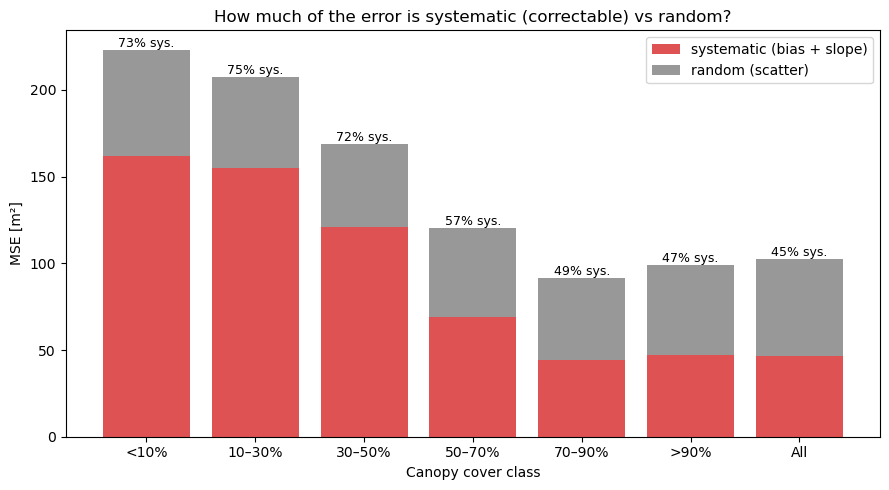

  [figure] outputs/figures/12b_error_decomposition.png

--- MSE decomposition ---
             MSE_sys  MSE_rand  sys_%
cover_class                          
<10%          161.96     61.20  72.58
10–30%        154.71     52.79  74.56
30–50%        120.97     47.54  71.79
50–70%         69.01     51.13  57.44
70–90%         44.35     46.92  48.59
>90%           46.84     52.04  47.37
All            46.40     56.32  45.17


In [27]:
with section("12b. Error decomposition: systematic vs random (Willmott 1981)"):
    def decompose(g, ref=REF):
        o, p_ = g[ref].values, g["fh"].values
        ok_ = np.isfinite(o) & np.isfinite(p_)
        o, p_ = o[ok_], p_[ok_]
        if len(o) < 30:
            return pd.Series({"MSE_sys": np.nan, "MSE_rand": np.nan})
        b, a = np.polyfit(o, p_, 1)
        p_hat = a + b * o
        return pd.Series({"MSE_sys": np.mean((p_hat - o) ** 2), "MSE_rand": np.mean((p_ - p_hat) ** 2)})

    dec = dens.groupby("cover_class", observed=True)[[REF, "fh"]].apply(decompose)
    dec.index = dec.index.astype(str)
    dec.loc["All"] = decompose(dens)
    dec["sys_%"] = 100 * dec["MSE_sys"] / (dec["MSE_sys"] + dec["MSE_rand"])
    fig, ax = plt.subplots(figsize=(9, 5))
    xi = np.arange(len(dec))
    ax.bar(xi, dec["MSE_sys"], label="systematic (bias + slope)", color="tab:red", alpha=0.8)
    ax.bar(xi, dec["MSE_rand"], bottom=dec["MSE_sys"], label="random (scatter)", color="tab:grey", alpha=0.8)
    for i, (s_, tot) in enumerate(zip(dec["sys_%"], dec["MSE_sys"] + dec["MSE_rand"])):
        if np.isfinite(s_):
            ax.text(i, tot, f"{s_:.0f}% sys.", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(xi, dec.index)
    ax.set_xlabel("Canopy cover class"); ax.set_ylabel("MSE [m²]")
    ax.set_title("How much of the error is systematic (correctable) vs random?"); ax.legend()
    plt.tight_layout(); save(fig, "12b_error_decomposition")
    rep_table("MSE decomposition", dec, "12b_error_decomposition")


12c. BIOMASS quality layer filtering


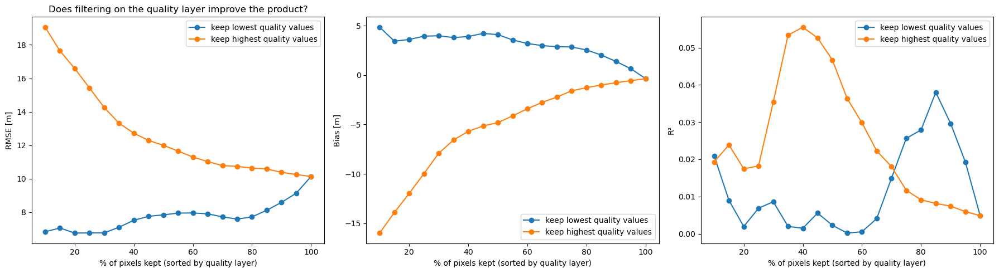

  [figure] outputs/figures/12c_quality_filtering.png

--- Quality filtering curves ---
                                frac   RMSE   bias    R2  threshold
direction                   i                                      
keep lowest quality values  0   0.10   6.83   4.87  0.02       0.00
                            1   0.15   7.06   3.45  0.01       0.00
                            2   0.20   6.76   3.62  0.00       0.00
                            3   0.25   6.76   3.96  0.01       0.00
                            4   0.30   6.77   4.00  0.01       0.00
                            5   0.35   7.10   3.81  0.00       0.00
                            6   0.40   7.52   3.92  0.00       0.00
                            7   0.45   7.76   4.24  0.01       0.00
                            8   0.50   7.84   4.11  0.00       0.07
                            9   0.55   7.95   3.57  0.00       0.37
                            10  0.60   7.96   3.21  0.00       0.68
                            1

In [28]:
with section("12c. BIOMASS quality layer filtering"):
    qd = dens.dropna(subset=["fh_quality"])
    fracs = np.linspace(0.1, 1.0, 19)
    curves = {}
    for label, asc in [("keep lowest quality values", True), ("keep highest quality values", False)]:
        srt_q = qd.sort_values("fh_quality", ascending=asc)
        rows = []
        for f in fracs:
            k = srt_q.iloc[: max(int(f * len(srt_q)), 3)]
            s_ = vstats(k[REF], k["fh"])
            rows.append({"frac": f, "RMSE": s_["RMSE"], "bias": s_["bias"], "R2": s_["R2"],
                         "threshold": k["fh_quality"].iloc[-1]})
        curves[label] = pd.DataFrame(rows)
    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    for label, cdf in curves.items():
        for a, k in zip(ax, ["RMSE", "bias", "R2"]):
            a.plot(100 * cdf["frac"], cdf[k], "o-", label=label)
    for a, t in zip(ax, ["RMSE [m]", "Bias [m]", "R²"]):
        a.set_xlabel("% of pixels kept (sorted by quality layer)"); a.set_ylabel(t); a.legend()
    ax[0].set_title("Does filtering on the quality layer improve the product?")
    plt.tight_layout(); save(fig, "12c_quality_filtering")
    rep_table("Quality filtering curves", pd.concat(curves, names=["direction", "i"]), "12c_quality_filtering")


12d. Scale dependence (aggregation to coarser blocks)


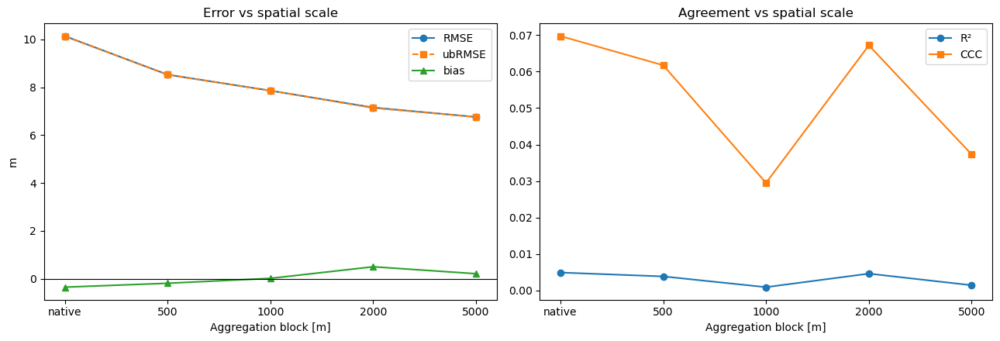

  [figure] outputs/figures/12d_scale_dependence.png

--- Metrics vs aggregation scale ---
             n  ALS_mean  FH_mean  bias  median_resid   MAE   RMSE  ubRMSE  NMAD  rel_RMSE_%   R2   CCC  slope  intercept  within_5m_%  within_10m_%
block_m                                                                                                                                             
native   67181     23.83    23.48 -0.35          2.37  7.67  10.14   10.13  6.97       42.53  0.0  0.07   0.07      21.77        43.64         74.27
500       3130     23.90    23.71 -0.19          2.68  6.72   8.52    8.52  5.69       35.66  0.0  0.06   0.06      22.25        46.58         80.26
1000      1125     24.00    24.02  0.02          2.90  6.31   7.86    7.86  4.77       32.74  0.0  0.03   0.03      23.34        49.16         83.11
2000       502     24.04    24.54  0.50          3.04  5.81   7.15    7.13  3.94       29.75  0.0  0.07   0.06      23.01        51.79         85.46
5000       231  

In [29]:
with section("12d. Scale dependence (aggregation to coarser blocks)"):
    BLOCKS_M = [0, 500, 1000, 2000, 5000]
    MIN_PIX_BLOCK = 3
    rows = []
    for bm in BLOCKS_M:
        if bm == 0:
            agg_df = dens[[REF, "fh"]]
        else:
            dlat = bm / 111_320
            dlon = bm / (111_320 * np.cos(np.deg2rad(dens["lat"])))
            key = pd.DataFrame({"tile": dens["id_als"], "iy": np.floor(dens["lat"] / dlat).astype(int),
                                "ix": np.floor(dens["lon"] / dlon).astype(int)})
            g = dens[[REF, "fh"]].groupby([key["tile"], key["iy"], key["ix"]])
            agg_df = g.mean()[g.size() >= MIN_PIX_BLOCK]
        rows.append({"block_m": bm if bm else "native", **vstats(agg_df[REF], agg_df["fh"])})
    scale_tab = pd.DataFrame(rows).set_index("block_m")
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    lbl = scale_tab.index.astype(str)
    ax[0].plot(lbl, scale_tab["RMSE"], "o-", label="RMSE")
    ax[0].plot(lbl, scale_tab["ubRMSE"], "s--", label="ubRMSE")
    ax[0].plot(lbl, scale_tab["bias"], "^-", label="bias")
    ax[0].axhline(0, color="k", lw=0.8)
    ax[0].set_xlabel("Aggregation block [m]"); ax[0].set_ylabel("m"); ax[0].legend(); ax[0].set_title("Error vs spatial scale")
    ax[1].plot(lbl, scale_tab["R2"], "o-", label="R²")
    ax[1].plot(lbl, scale_tab["CCC"], "s-", label="CCC")
    ax[1].set_xlabel("Aggregation block [m]"); ax[1].legend(); ax[1].set_title("Agreement vs spatial scale")
    plt.tight_layout(); save(fig, "12d_scale_dependence")
    rep_table("Metrics vs aggregation scale", scale_tab, "12d_scale_dependence")


12e. 95% confidence intervals (bootstrap over tiles)


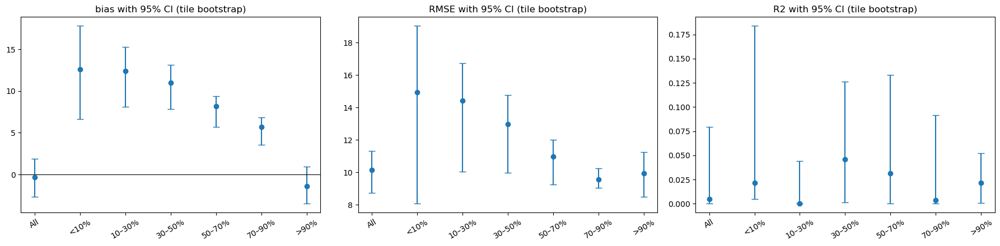

  [figure] outputs/figures/12e_bootstrap_ci.png

--- Bootstrap confidence intervals ---
        n_tiles   bias  bias_lo  bias_hi   RMSE  RMSE_lo  RMSE_hi    R2  R2_lo  R2_hi
All       102.0  -0.35    -2.65     1.90  10.14     8.73    11.31  0.00    0.0   0.08
<10%        5.0  12.60     6.62    17.81  14.94     8.06    19.03  0.02    0.0   0.18
10–30%      5.0  12.41     8.12    15.29  14.40    10.04    16.72  0.00    0.0   0.04
30–50%     15.0  11.00     7.87    13.10  12.98     9.96    14.77  0.05    0.0   0.13
50–70%     26.0   8.20     5.71     9.41  10.96     9.23    12.00  0.03    0.0   0.13
70–90%     70.0   5.69     3.57     6.86   9.55     9.05    10.26  0.00    0.0   0.09
>90%      102.0  -1.38    -3.51     0.92   9.94     8.48    11.25  0.02    0.0   0.05


In [30]:
with section("12e. 95% confidence intervals (bootstrap over tiles)"):
    N_BOOT = 1000
    rng = np.random.default_rng(42)

    def tile_sums(df_, ref=REF):
        d = df_[[ref, "fh", "id_als"]].dropna()
        x_, y_ = d[ref], d["fh"]
        return (pd.DataFrame({"n": 1, "x": x_, "y": y_, "xx": x_ * x_, "yy": y_ * y_, "xy": x_ * y_,
                              "e": y_ - x_, "ee": (y_ - x_) ** 2, "id_als": d["id_als"]})
                .groupby("id_als").sum())

    def metrics_from_sums(S):
        n = S["n"]
        mx, my = S["x"] / n, S["y"] / n
        cov = S["xy"] / n - mx * my
        vx, vy = S["xx"] / n - mx ** 2, S["yy"] / n - my ** 2
        return {"bias": S["e"] / n, "RMSE": np.sqrt(S["ee"] / n), "R2": cov ** 2 / (vx * vy)}

    def boot_ci(df_):
        ts = tile_sums(df_)
        if len(ts) < 3:
            return None
        idx = rng.integers(0, len(ts), size=(N_BOOT, len(ts)))
        A = ts.values
        S = pd.DataFrame(np.stack([A[i].sum(0) for i in idx]), columns=ts.columns)
        est, bs = metrics_from_sums(ts.sum()), metrics_from_sums(S)
        return ({k: est[k] for k in est} | {f"{k}_lo": np.percentile(bs[k], 2.5) for k in bs}
                | {f"{k}_hi": np.percentile(bs[k], 97.5) for k in bs} | {"n_tiles": len(ts)})

    ci = {"All": boot_ci(dens)}
    for c in COVER_LABELS:
        r_ = boot_ci(dens[dens["cover_class"] == c])
        if r_:
            ci[c] = r_
    ci = pd.DataFrame(ci).T
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
    for a, k in zip(ax, ["bias", "RMSE", "R2"]):
        xi = np.arange(len(ci))
        a.errorbar(xi, ci[k], yerr=[ci[k] - ci[f"{k}_lo"], ci[f"{k}_hi"] - ci[k]], fmt="o", capsize=4, color="tab:blue")
        a.set_xticks(xi, ci.index, rotation=30); a.set_title(f"{k} with 95% CI (tile bootstrap)")
        if k == "bias":
            a.axhline(0, color="k", lw=0.8)
    plt.tight_layout(); save(fig, "12e_bootstrap_ci")
    rep_table("Bootstrap confidence intervals",
              ci[["n_tiles", "bias", "bias_lo", "bias_hi", "RMSE", "RMSE_lo", "RMSE_hi", "R2", "R2_lo", "R2_hi"]],
              "12e_bootstrap_ci")

### 12f. KEY NUMBERS FOR THE SLIDES

In [31]:
with section("12f. KEY NUMBERS FOR THE SLIDES"):
    s_all = vstats(dens[REF], dens["fh"])
    rep(f"Validation of BIOMASS L2A FH against ALS ({REF}), "
        f"{dens['id_als'].nunique()} tiles / {dens['site'].nunique()} sites / {len(dens):,} pixels")
    rep(f"  Overall: bias {s_all['bias']:.1f} m, RMSE {s_all['RMSE']:.1f} m ({s_all['rel_RMSE_%']:.0f}%), "
        f"R² {s_all['R2']:.2f}, slope {s_all['slope']:.2f}, {s_all['within_5m_%']:.0f}% within ±5 m")
    if "ci" in globals() and "All" in ci.index:
        rep(f"  95% CI (tile bootstrap): RMSE {ci.loc['All', 'RMSE_lo']:.1f}–{ci.loc['All', 'RMSE_hi']:.1f} m, "
            f"bias {ci.loc['All', 'bias_lo']:.1f}–{ci.loc['All', 'bias_hi']:.1f} m")
    if "fits" in globals():
        rep(f"  Log-log fit (ALS ≥ {MIN_ALS_H:g} m): FH = {fits.iloc[1]['a']:.2f}·ALS^{fits.iloc[1]['b']:.2f} "
            f"(R² log {fits.iloc[1]['R2_log_space']:.2f}); linear fit: FH = {fits.iloc[0]['b']:.2f}·ALS + "
            f"{fits.iloc[0]['a']:.1f} (R² {fits.iloc[0]['R2']:.2f})")
    if "cover_tab" in globals() and len(cover_tab):
        best_c, worst_c = cover_tab["RMSE"].idxmin(), cover_tab["RMSE"].idxmax()
        rep(f"  Best canopy cover class:  {best_c}  (RMSE {cover_tab.loc[best_c, 'RMSE']:.1f} m, "
            f"bias {cover_tab.loc[best_c, 'bias']:.1f} m)")
        rep(f"  Worst canopy cover class: {worst_c}  (RMSE {cover_tab.loc[worst_c, 'RMSE']:.1f} m, "
            f"bias {cover_tab.loc[worst_c, 'bias']:.1f} m)")
    if "dec" in globals():
        rep(f"  Systematic share of MSE: {dec.loc['All', 'sys_%']:.0f}%")
    if "scale_tab" in globals():
        rep(f"  RMSE native → {BLOCKS_M[-1]} m blocks: "
            f"{scale_tab['RMSE'].iloc[0]:.1f} → {scale_tab['RMSE'].iloc[-1]:.1f} m")


12f. KEY NUMBERS FOR THE SLIDES
Validation of BIOMASS L2A FH against ALS (als_mean), 102 tiles / 1 sites / 67,181 pixels
  Overall: bias -0.3 m, RMSE 10.1 m (43%), R² 0.00, slope 0.07, 44% within ±5 m
  95% CI (tile bootstrap): RMSE 8.7–11.3 m, bias -2.7–1.9 m
  Log-log fit (ALS ≥ 1 m): FH = 18.47·ALS^0.08 (R² log 0.00); linear fit: FH = 0.00·ALS + 23.6 (R² 0.00)
  Best canopy cover class:  70–90%  (RMSE 9.6 m, bias 5.7 m)
  Worst canopy cover class: <10%  (RMSE 14.9 m, bias 12.6 m)
  Systematic share of MSE: 45%
  RMSE native → 5000 m blocks: 10.1 → 6.8 m


In [32]:
t_end = dt.datetime.now()
rep("\n" + "=" * 90)
rep(f"Finished {t_end:%Y-%m-%d %H:%M}  (run time {(t_end - t_start).total_seconds() / 60:.1f} min)")
rep(f"{len(FIGURES)} figures in {FIG_DIR}/:")
for f in FIGURES:
    rep(f"  {f}")
rep(f"Tables: {TAB_DIR}/   Maps: {MAP_DIR}/   Pixel data: {DATA_DIR}/")
if FAILED_SECTIONS:
    rep(f"!! {len(FAILED_SECTIONS)} section(s) failed (see errors above): {FAILED_SECTIONS}")
else:
    rep("All sections completed.")


Finished 2026-10-16 08:17  (run time 1.6 min)
20 figures in outputs/figures/:
  04_footprints_time_gap.png
  07a_single_tile_maps.png
  07b_single_tile_scatter_log_hist_resid.png
  07c_single_tile_hist_linear.png
  08c_scatter_linear_and_loglog.png
  09a_map_bias_rmse_per_tile.png
  09b_map_residual_grid.png
  09d_best_tile.png
  09d_worst_tile.png
  10_drivers.png
  11c_metrics_by_canopy_cover.png
  11d_scatter_by_canopy_cover.png
  11e_height_x_cover_matrix.png
  11f_reference_definition.png
  11g_cover_continuous_heterogeneity.png
  11h_sites_tiles.png
  12b_error_decomposition.png
  12c_quality_filtering.png
  12d_scale_dependence.png
  12e_bootstrap_ci.png
Tables: outputs/tables/   Maps: outputs/maps/   Pixel data: outputs/data/
All sections completed.
